#Clustering

In [1]:
print("Hello clustering world")

Hello clustering world


#Data

## Data folder

In this step we retrieve the data from the folder where it is located

In [2]:
# Connect Google Colab to Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

path = '/content/drive/MyDrive/ML_proj/Projeto/'

Mounted at /content/drive


## Libraries

Here, we install and import the libraries required for the analysis

### Install

In [3]:
# Step 1 - Install pandas using the pip install command
#!pip install pandas
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn

### Import

In [4]:
# Step 2 - Import relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from tqdm.notebook import tqdm, trange
from sklearn.cluster import KMeans
import scipy.cluster.hierarchy as sch
#Use the command '%matplotlib inline' after importing matplotlib to guarantee that the plots are on the notebook


#set seaborn as default style for visualizations
sns.set()

## File access

Check the excel file provided

In [5]:
world_citizens_scaled = pd.read_excel(path + 'Data/wd_ct_scaled_second.xlsx')

#as a good practice, we avoided working on the dataset imported and created a copy instead
wd_ct_scaled = world_citizens_scaled.copy()
wd_ct_scaled.head(5)

,citizen_id,country,education_level,financial_wellness_index,investments_risk_appetite,last_year_charity_donations,name,stress_management_score,gender,Is_male,...,donates,log_environmental_awareness_rating,log_investment_portfolio_value,is_investor,log_investments_risk_tolerance,log_social_media_influence_score,log_avg_monthly_entertainment_expenses,log_avg_weekly_exercise_hours,log_health_consciousness_rating,log_well_being_level
0,1,Brazil,0.389315,0.576607,0.780114,0.000000,Mafalda,0.457351,Female,0,...,0,0.194221,0.387871,Common,0.917684,0.375446,0.465811,0.000000,0.259400,0.490244
1,2,New Zealand,0.345058,0.458003,0.837244,0.000000,Olive,0.242076,Female,0,...,0,0.207002,0.000000,No,0.819880,0.332630,0.504392,0.053708,0.294649,0.542269
2,3,Germany,0.662082,0.047127,0.480487,0.000000,Esther,0.615300,Female,0,...,0,0.216001,0.678226,Common,0.339357,0.701466,0.698048,0.047075,0.145913,0.533085
3,4,Germany,0.597648,0.189868,0.820323,0.020218,Ramon,0.495060,Male,1,...,1,0.209029,0.692416,Common,0.483279,0.516673,0.734570,0.018064,0.236369,0.645044
4,5,Turkey,0.427562,0.208099,0.503443,0.000000,Koray,0.325015,Male,1,...,0,0.345758,0.693531,Common,0.271762,0.646108,0.396071,0.360713,0.085719,0.316992


#Useful functions

This function assists us with the visualizations of the clusters by variable

In [6]:
def cluster_visualization(df, label_columns, figsize, compar_titles=None):
    if compar_titles == None:
        compar_titles = [""]*len(label_columns)

    fig, axes = plt.subplots(nrows=len(label_columns), ncols=2, figsize=figsize, squeeze=False)
    for ax, label, titl in zip(axes, label_columns, compar_titles):
        # Filtering df
        drop_cols = [i for i in label_columns if i!=label]
        dfax = df.drop(drop_cols, axis=1)

        # Getting the cluster centroids and counts
        centroids = dfax.groupby(by=label, as_index=False).mean()
        counts = dfax.groupby(by=label, as_index=False).count().iloc[:,[0,1]]
        counts.columns = [label, "counts"]
        color = sns.color_palette('Dark2')

        # Setting Data
        pd.plotting.parallel_coordinates(centroids, label, color=color, ax=ax[0])
        sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)

        #Setting Layout
        handles, _ = ax[0].get_legend_handles_labels()
        cluster_labels = ["Cluster {}".format(i) for i in range(len(handles))]
        ax[0].annotate(text=titl, xy=(0.95,1.1), xycoords='axes fraction', fontsize=16, fontweight = 'heavy')
        ax[0].legend(handles, cluster_labels) # Adaptable to number of clusters
        ax[0].axhline(color="black", linestyle="--")
        ax[0].set_title("Cluster Means - {} Clusters".format(len(handles)), fontsize=16)
        ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=-20)
        ax[1].set_xticklabels(cluster_labels)
        ax[1].set_xlabel("")
        ax[1].set_ylabel("Absolute Frequency")
        ax[1].set_title("Cluster Sizes - {} Clusters".format(len(handles)), fontsize=16)


    plt.subplots_adjust(hspace=0.4, top=0.90, bottom = 0.2)
    plt.suptitle("Cluster Profiling", fontsize=23)
    plt.show()

#Profiling

In order to have better intrepertability of the data and help us decide which variables we should use to do the clustering we decided to do three different profilings, one regarding social aspects, other economic aspects, and health aspects

For both the different profilings and the the whole data clustering we will use the Kmeans method

First we created a temporary dataset that contained only metric features

In [7]:
lst = ['citizen_id','country','is_investor','name','gender','donates','Is_male','Is_female']
wd_ct_metric = wd_ct_scaled.drop(columns=lst)

##Economic profiling

For the economic profiling we decided to use the following variables:

-financial_wellness_index

-investments_risk_appetite

-log_investment_portfolio_value

-log_investments_risk_tolerance

-log_avg_monthly_entertainment_expenses

In [8]:
#eco prespective (economic)
#create a subset of the clustered data set with only economy related variables
eco_clustered = wd_ct_scaled[['financial_wellness_index', 'investments_risk_appetite','log_investment_portfolio_value', 'log_investments_risk_tolerance','log_avg_monthly_entertainment_expenses']]

Checking again correlations between the variables chosen, for clarity purposes

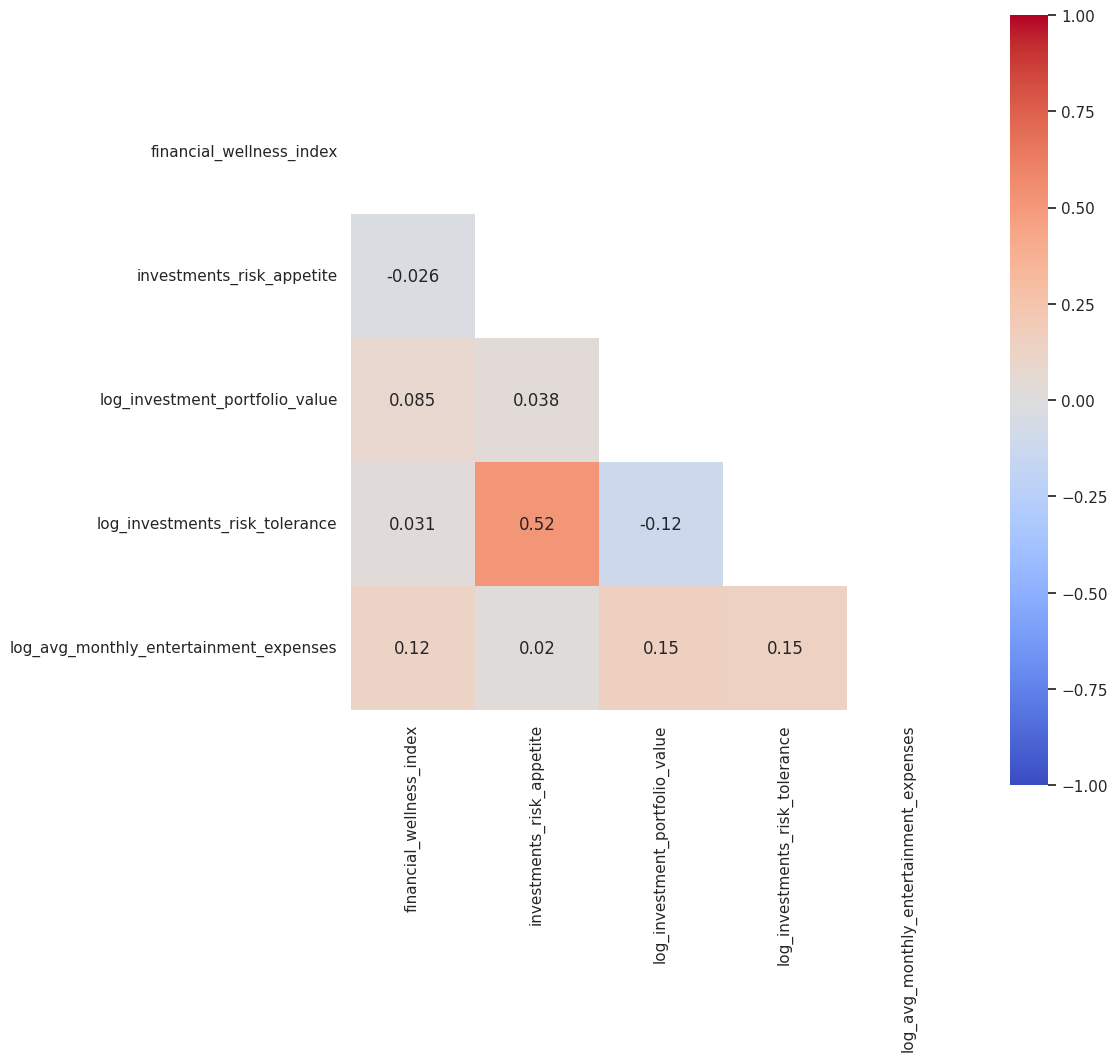

In [9]:
#see the correlation between variables using np
mask = np.zeros_like(eco_clustered.corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(10,10))
    ax = sns.heatmap(eco_clustered.corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

Because of the correlation matrix we concluded that no multicolinearity was present among the variables for this profiling except a high correlation between risk tolerance and risk appetite

Ploting the elbow method to help us deciding which K to use during Kmeans

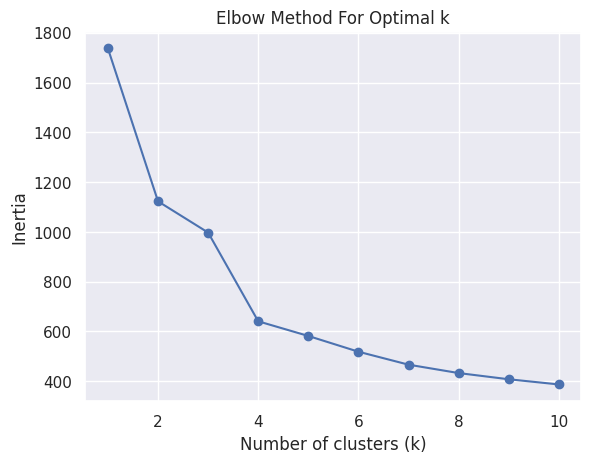

In [10]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(eco_clustered)  # 'data' is your dataset (numpy or pandas)
    inertias.append(kmeans.inertia_)

# Plot
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

Ploting the dendogram to also support our decision regarding the ideal K

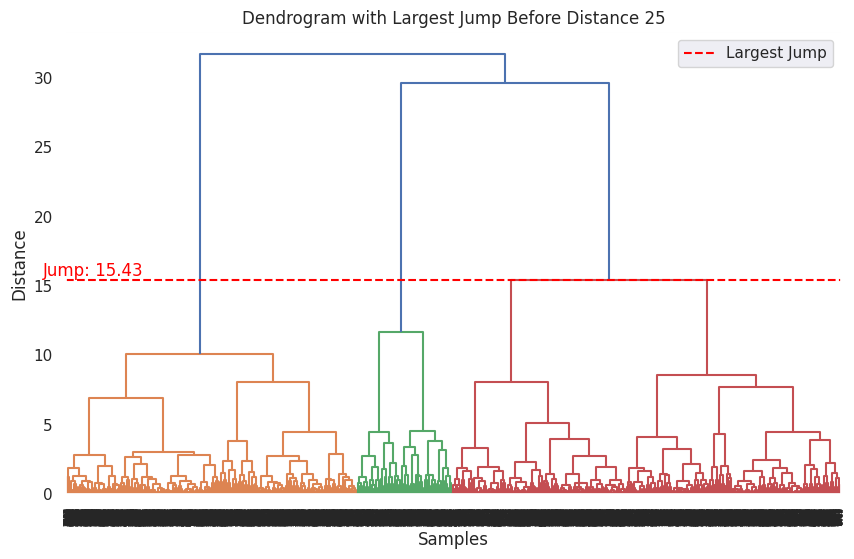

In [11]:
# Assuming wd_ct_scaled and metric_cols are already defined
linkage_matrix = sch.linkage(eco_clustered, method='ward')

# Create the dendrogram
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix)

# Calculate the distances (the last column of the linkage matrix)
distances = linkage_matrix[:, 2]

# Filter distances to find the largest jump before distance 25
filtered_indices = np.where(distances <=25)[0]
if len(filtered_indices) > 0:
    filtered_distances = distances[filtered_indices]
    max_jump_index = np.argmax(np.diff(filtered_distances))
    max_jump_value = filtered_distances[max_jump_index + 1]  # +1 because np.diff reduces the array size by 1

    # Get the x-coordinate for the largest jump
    x_coord = filtered_indices[max_jump_index + 1]  # +1 to account for the 0-based index

    # Add a horizontal line to mark the largest jump
    plt.axhline(y=max_jump_value, color='red', linestyle='--', label='Largest Jump')

    # Optionally, add a text annotation
    plt.text(x_coord, max_jump_value, f'Jump: {max_jump_value:.2f}', color='red',
             verticalalignment='bottom', horizontalalignment='right')

# Add title and labels
plt.title("Dendrogram with Largest Jump Before Distance 25")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.legend()
plt.show()

By looking to both the elbow method and the dendogram we decided to proceed with 3 clusters

In [12]:
kmeans0 = KMeans(n_clusters = 3, random_state = 0).fit(eco_clustered)

In [13]:
eco_clustered['cluster'] = kmeans0.predict(eco_clustered)

<ipython-input-13-903874769>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  eco_clustered['cluster'] = kmeans0.predict(eco_clustered)


Visualizations of both the number of observations and the mean of each variable by cluster

<ipython-input-6-755128967>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:19: UserWarning: The palette list has more values (8) than needed (3), which may not be intended.
  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(cluster_labels)


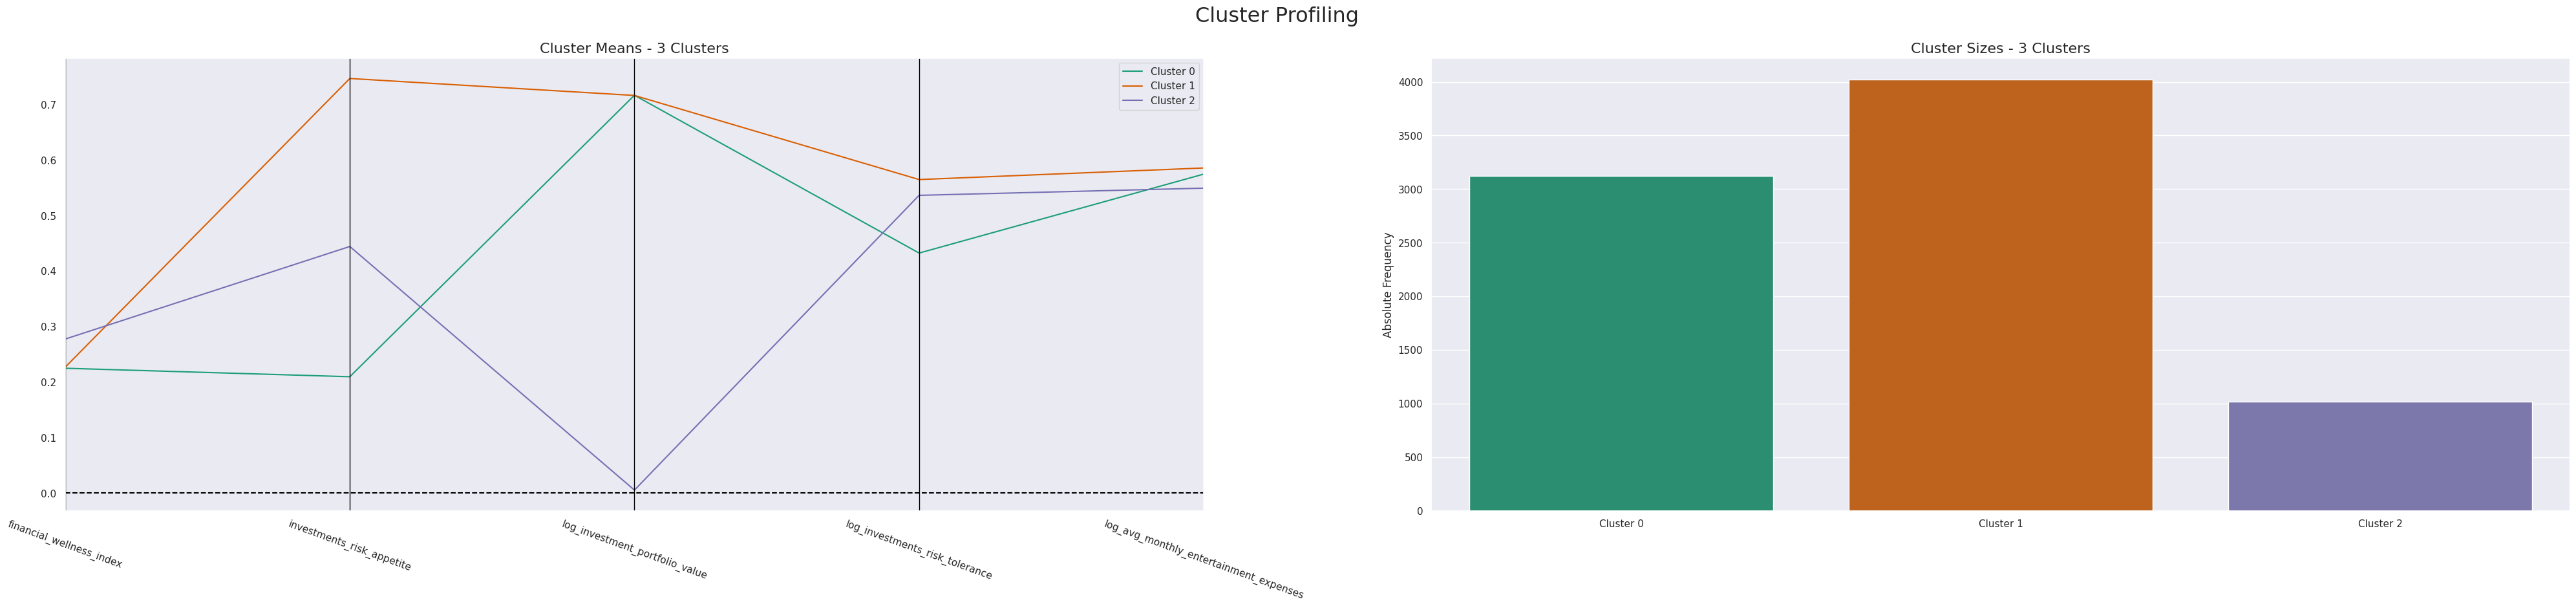

In [14]:
#Visualization
cluster_visualization(eco_clustered, ["cluster"], figsize=(50, 10))

With these visualizations we can conclude that most variables seem to differenciate the clusters with the exceptions of financial_wellness_index and log_avg_monthly_entertainment_expenses.

We can also conclude that cluster 2 distincs itself by having less observations than cluster 1 and 0

##Social Profiling

For the Social profiling we decided to use the following variables:

-log_environmental_awareness_rating

-log_social_media_influence_score

-last_year_charity_donations

-education_level


In [15]:
#social prespective
#create a subset of the clustered data set with only personal/social related variables
social_clustered = wd_ct_scaled[['log_environmental_awareness_rating', 'log_social_media_influence_score', 'last_year_charity_donations', 'education_level']]

Checking correlations between the variables chosen, for clarity purposes

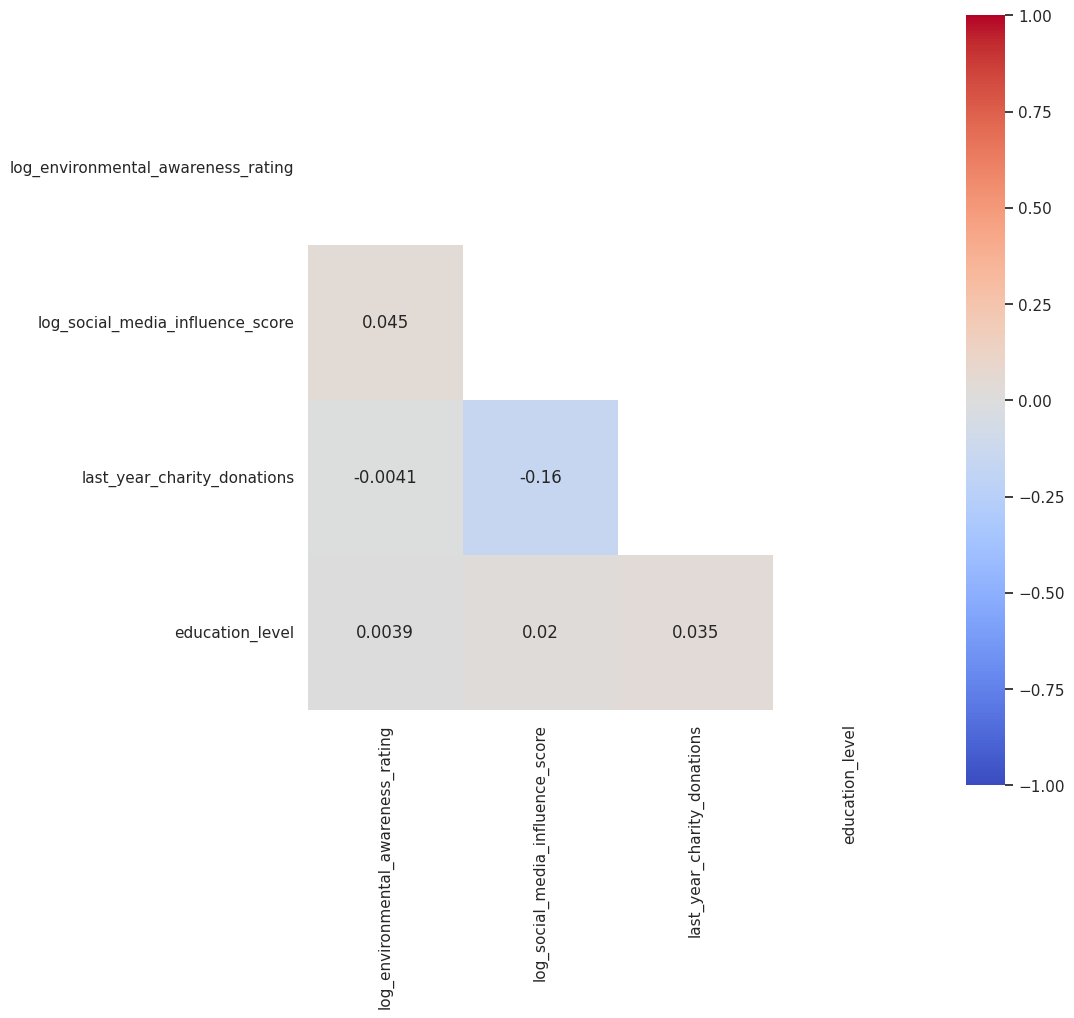

In [16]:
#see the correlation between variables using np
mask = np.zeros_like(social_clustered.corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(10,10))
    ax = sns.heatmap(social_clustered.corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

We can conclude that with this set of variables we have good colinearity values, not being needed to take off any of them

Ploting the elbow method to help us deciding which K to use during Kmeans

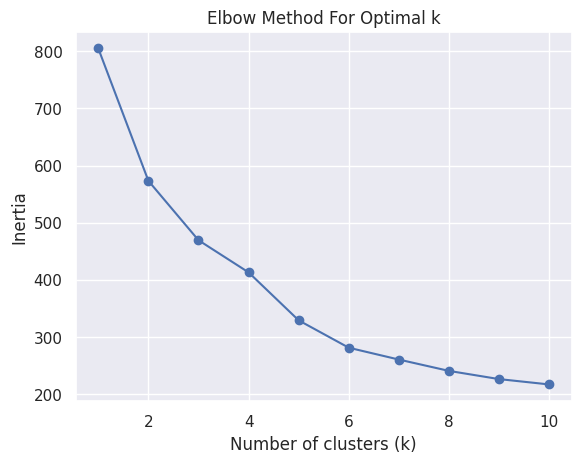

In [17]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(social_clustered)  # 'data' is your dataset (numpy or pandas)
    inertias.append(kmeans.inertia_)

# Plot
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

Ploting the Dendogram to give us additional insight to decide which K to use during Kmeans

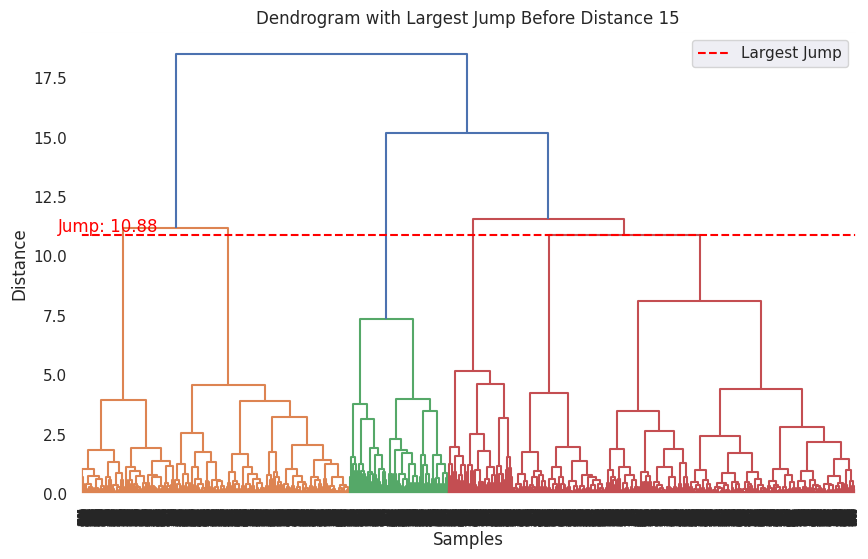

In [18]:
# Assuming wd_ct_scaled and metric_cols are already defined
linkage_matrix = sch.linkage(social_clustered, method='ward')

# Create the dendrogram
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix)

# Calculate the distances (the last column of the linkage matrix)
distances = linkage_matrix[:, 2]

# Filter distances to find the largest jump before distance 15
filtered_indices = np.where(distances <= 15)[0]
if len(filtered_indices) > 0:
    filtered_distances = distances[filtered_indices]
    max_jump_index = np.argmax(np.diff(filtered_distances))
    max_jump_value = filtered_distances[max_jump_index + 1]  # +1 because np.diff reduces the array size by 1

    # Get the x-coordinate for the largest jump
    x_coord = filtered_indices[max_jump_index + 1]  # +1 to account for the 0-based index

    # Add a horizontal line to mark the largest jump
    plt.axhline(y=max_jump_value, color='red', linestyle='--', label='Largest Jump')

    # Optionally, add a text annotation
    plt.text(x_coord, max_jump_value, f'Jump: {max_jump_value:.2f}', color='red',
             verticalalignment='bottom', horizontalalignment='right')

# Add title and labels
plt.title("Dendrogram with Largest Jump Before Distance 15")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.legend()
plt.show()

By looking to both the elbow method and the dendogram we decided to proceed with 4 clusters

In [19]:
kmeans0 = KMeans(n_clusters = 4, random_state = 100).fit(social_clustered)

In [20]:
social_clustered['cluster'] = kmeans0.predict(social_clustered)

<ipython-input-20-3432348277>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  social_clustered['cluster'] = kmeans0.predict(social_clustered)


Visualizations of both the number of observations and the mean of each variable by cluster

<ipython-input-6-755128967>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:19: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(cluster_labels)


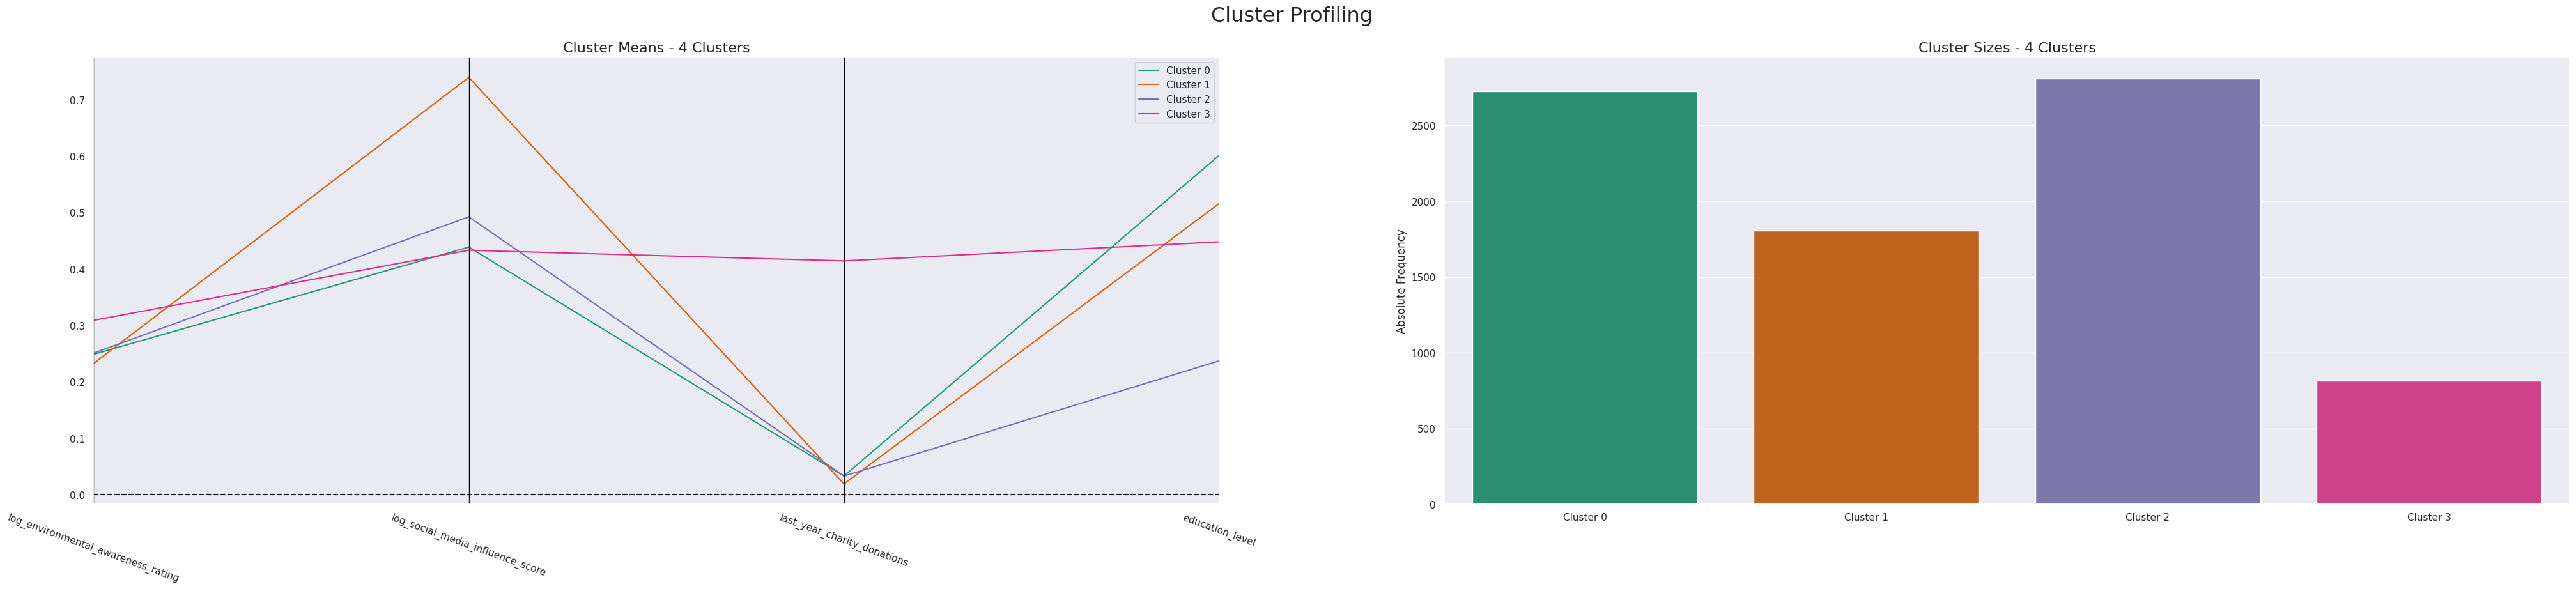

In [21]:
#Visualization
cluster_visualization(social_clustered, ["cluster"], figsize=(50, 10))

After analyzing the first graph we decided to test again this profiling but without the enviromental awareness, as it seemed to not influence much in the differentiation of the clusters

In [22]:
#social prespective
#create a subset of the clustered data set with only personal/social related variables
social_clustered = wd_ct_scaled[['log_social_media_influence_score', 'education_level', 'last_year_charity_donations']]

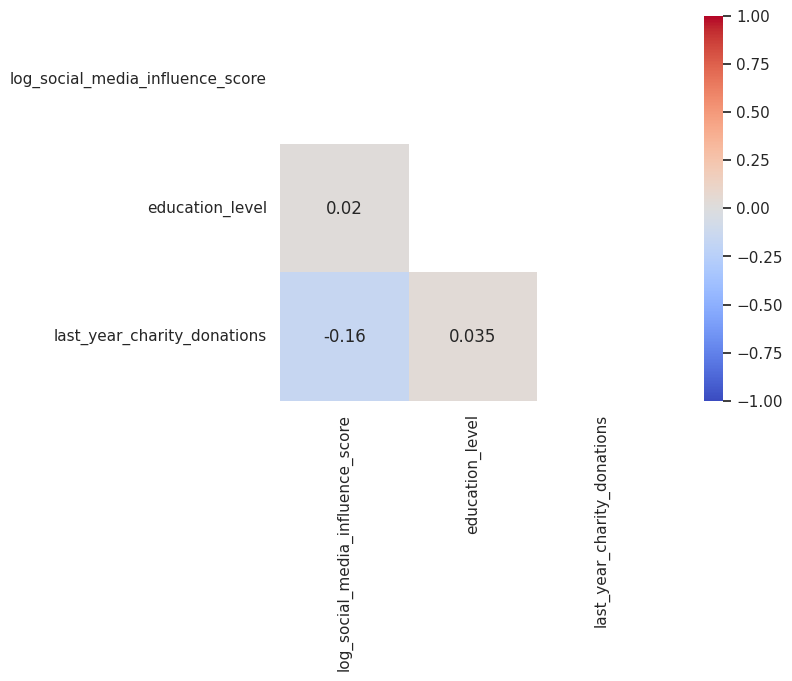

In [23]:
#see the correlation between variables using np
mask = np.zeros_like(social_clustered.corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(10,5))
    ax = sns.heatmap(social_clustered.corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

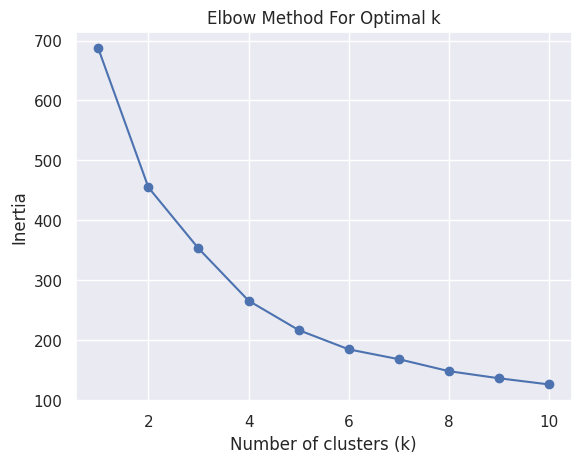

In [24]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(social_clustered)  # 'data' is your dataset (numpy or pandas)
    inertias.append(kmeans.inertia_)

# Plot
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

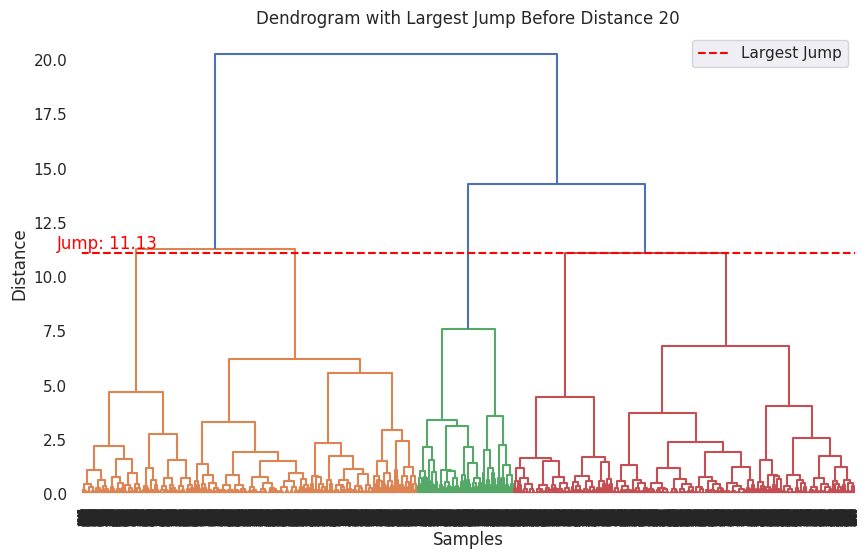

In [25]:
# Assuming wd_ct_scaled and metric_cols are already defined
linkage_matrix = sch.linkage(social_clustered, method='ward')

# Create the dendrogram
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix)

# Calculate the distances (the last column of the linkage matrix)
distances = linkage_matrix[:, 2]

# Filter distances to find the largest jump before distance 20
filtered_indices = np.where(distances <= 20)[0]
if len(filtered_indices) > 0:
    filtered_distances = distances[filtered_indices]
    max_jump_index = np.argmax(np.diff(filtered_distances))
    max_jump_value = filtered_distances[max_jump_index + 1]  # +1 because np.diff reduces the array size by 1

    # Get the x-coordinate for the largest jump
    x_coord = filtered_indices[max_jump_index + 1]  # +1 to account for the 0-based index

    # Add a horizontal line to mark the largest jump
    plt.axhline(y=max_jump_value, color='red', linestyle='--', label='Largest Jump')

    # Optionally, add a text annotation
    plt.text(x_coord, max_jump_value, f'Jump: {max_jump_value:.2f}', color='red',
             verticalalignment='bottom', horizontalalignment='right')

# Add title and labels
plt.title("Dendrogram with Largest Jump Before Distance 20")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.legend()
plt.show()

We decided to continue with 4 clusters

In [26]:
kmeans0 = KMeans(n_clusters = 4, random_state = 100).fit(social_clustered)

In [27]:
social_clustered['cluster'] = kmeans0.predict(social_clustered)

<ipython-input-27-3432348277>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  social_clustered['cluster'] = kmeans0.predict(social_clustered)


<ipython-input-6-755128967>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:19: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(cluster_labels)


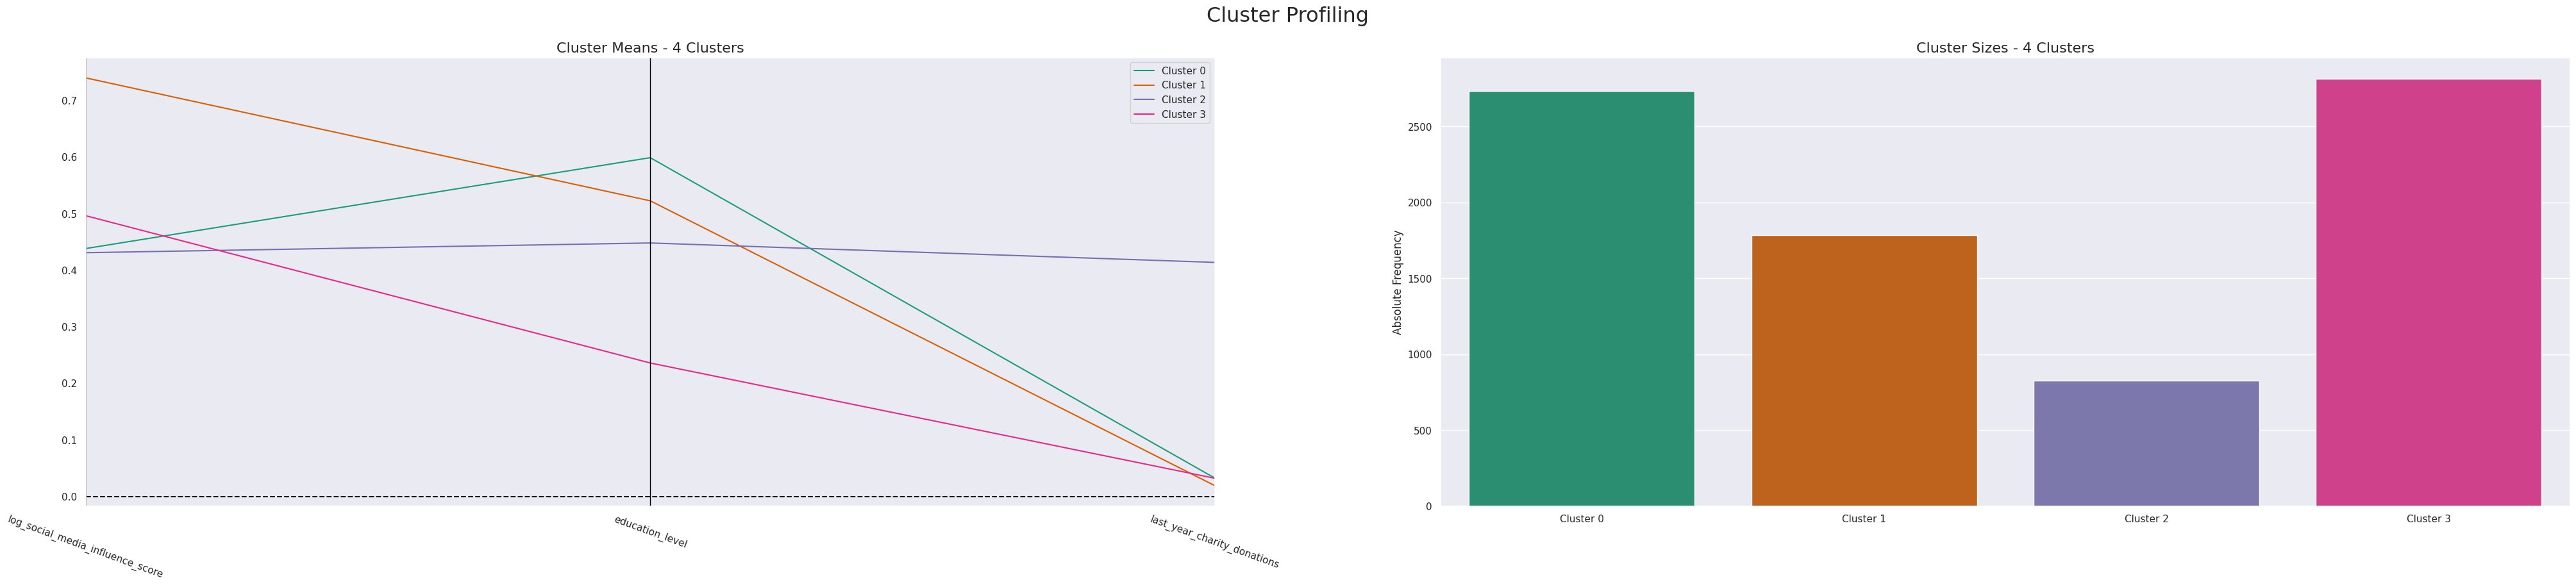

In [28]:
#Visualization
cluster_visualization(social_clustered, ["cluster"], figsize=(50, 10))

With the means graph we conclude that this three variables have an impact when differentiating the clusters and that cluster 2 has less observations than the others.

##Health Profiling

For the health profiling we decided to use the following variables:

-log_health_consciousness_rating

-log_well_being_level

-log_avg_weekly_exercise_hours

-age

-stress_management_score

In [29]:
#health prespective
#create a subset of the clustered data set with only personal/social related variables
health_clustered = wd_ct_scaled[['log_health_consciousness_rating', 'log_well_being_level', 'log_avg_weekly_exercise_hours','age', 'stress_management_score']]

Checking the correlations between this set of variables

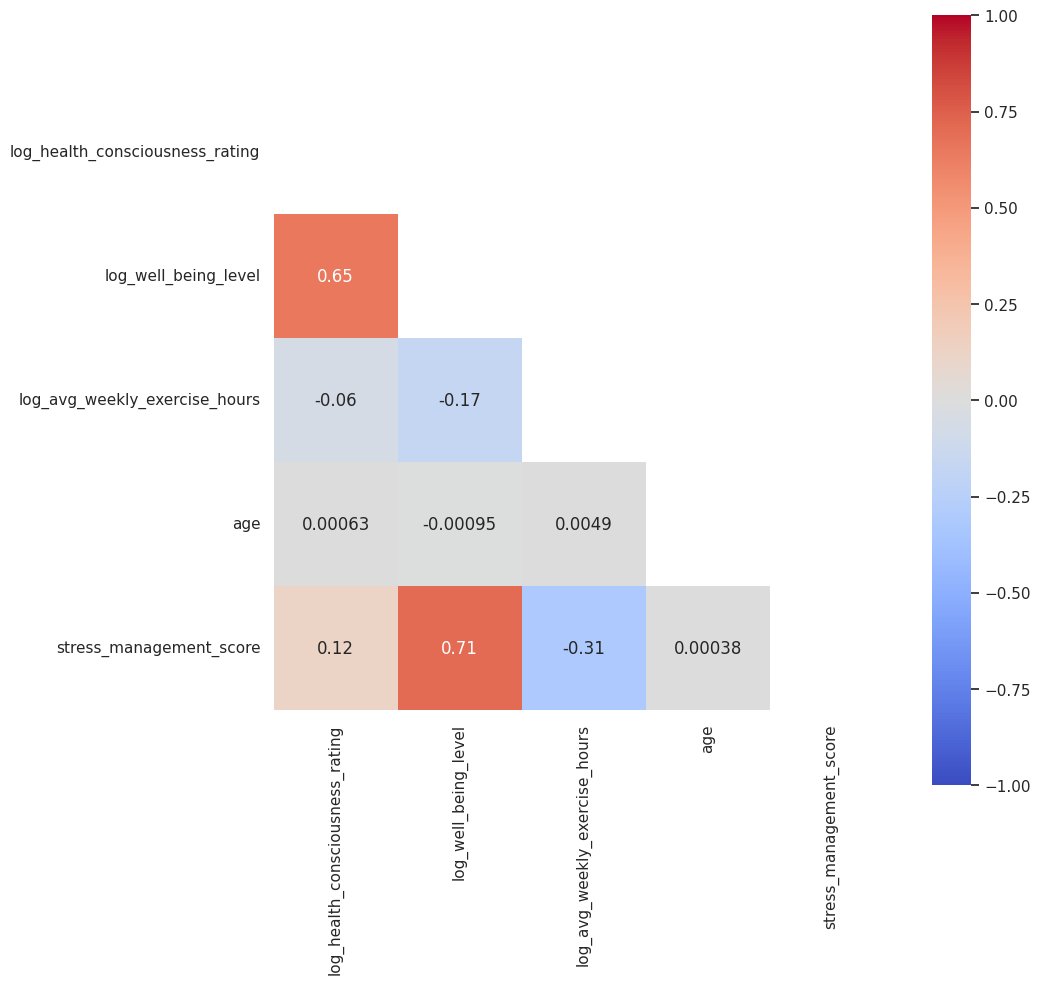

In [30]:
#see the correlation between variables using np
mask = np.zeros_like(health_clustered.corr("spearman"))
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    f, ax = plt.subplots(figsize=(10,10))
    ax = sns.heatmap(health_clustered.corr("spearman"),mask=mask, annot = True,cmap='coolwarm',square=True,vmin=-1, vmax=1)

With the graph we can see that there are some high values of multicoleniarity but not meaningful enough to take any of the variables out

Ploting the elbow method to help us deciding which K to use during Kmeans

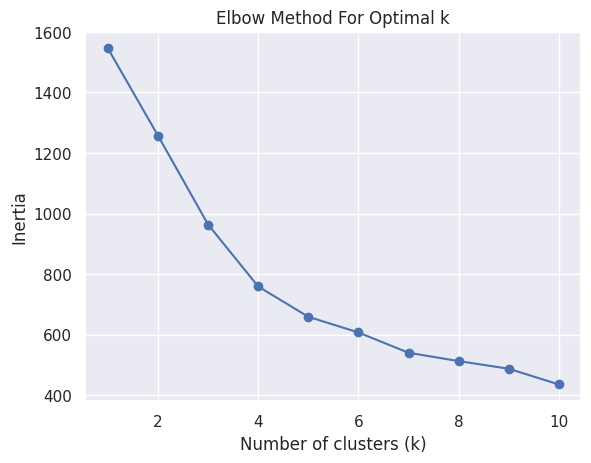

In [31]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(health_clustered)  # 'data' is your dataset (numpy or pandas)
    inertias.append(kmeans.inertia_)

# Plot
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

Ploting the dendogram to give us more insights to help to decide the K to use during Kmeans

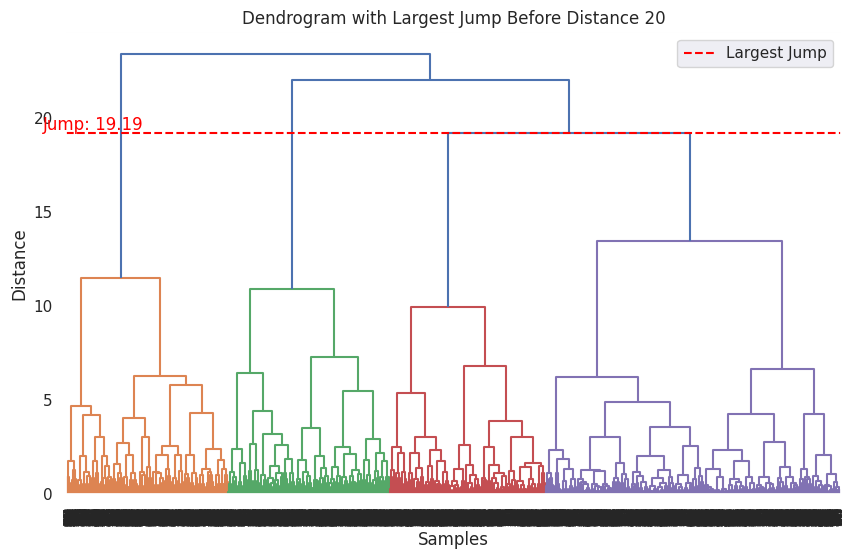

In [32]:
# Assuming wd_ct_scaled and metric_cols are already defined
linkage_matrix = sch.linkage(health_clustered, method='ward')

# Create the dendrogram
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix)

# Calculate the distances (the last column of the linkage matrix)
distances = linkage_matrix[:, 2]

# Filter distances to find the largest jump before distance 20
filtered_indices = np.where(distances < 20)[0]
if len(filtered_indices) > 0:
    filtered_distances = distances[filtered_indices]
    max_jump_index = np.argmax(np.diff(filtered_distances))
    max_jump_value = filtered_distances[max_jump_index + 1]  # +1 because np.diff reduces the array size by 1

    # Get the x-coordinate for the largest jump
    x_coord = filtered_indices[max_jump_index + 1]  # +1 to account for the 0-based index

    # Add a horizontal line to mark the largest jump
    plt.axhline(y=max_jump_value, color='red', linestyle='--', label='Largest Jump')

    # Optionally, add a text annotation
    plt.text(x_coord, max_jump_value, f'Jump: {max_jump_value:.2f}', color='red',
             verticalalignment='bottom', horizontalalignment='right')

# Add title and labels
plt.title("Dendrogram with Largest Jump Before Distance 20")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.legend()
plt.show()

By looking to both the elbow method and the dendogram we decided to proceed with 4 clusters

In [33]:
kmeans0 = KMeans(n_clusters = 4, random_state = 100).fit(health_clustered)

In [34]:
health_clustered['cluster'] = kmeans0.predict(health_clustered)

<ipython-input-34-2209411262>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  health_clustered['cluster'] = kmeans0.predict(health_clustered)


Visualizations of both the number of observations and the mean of each variable by cluster

<ipython-input-6-755128967>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:19: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(cluster_labels)


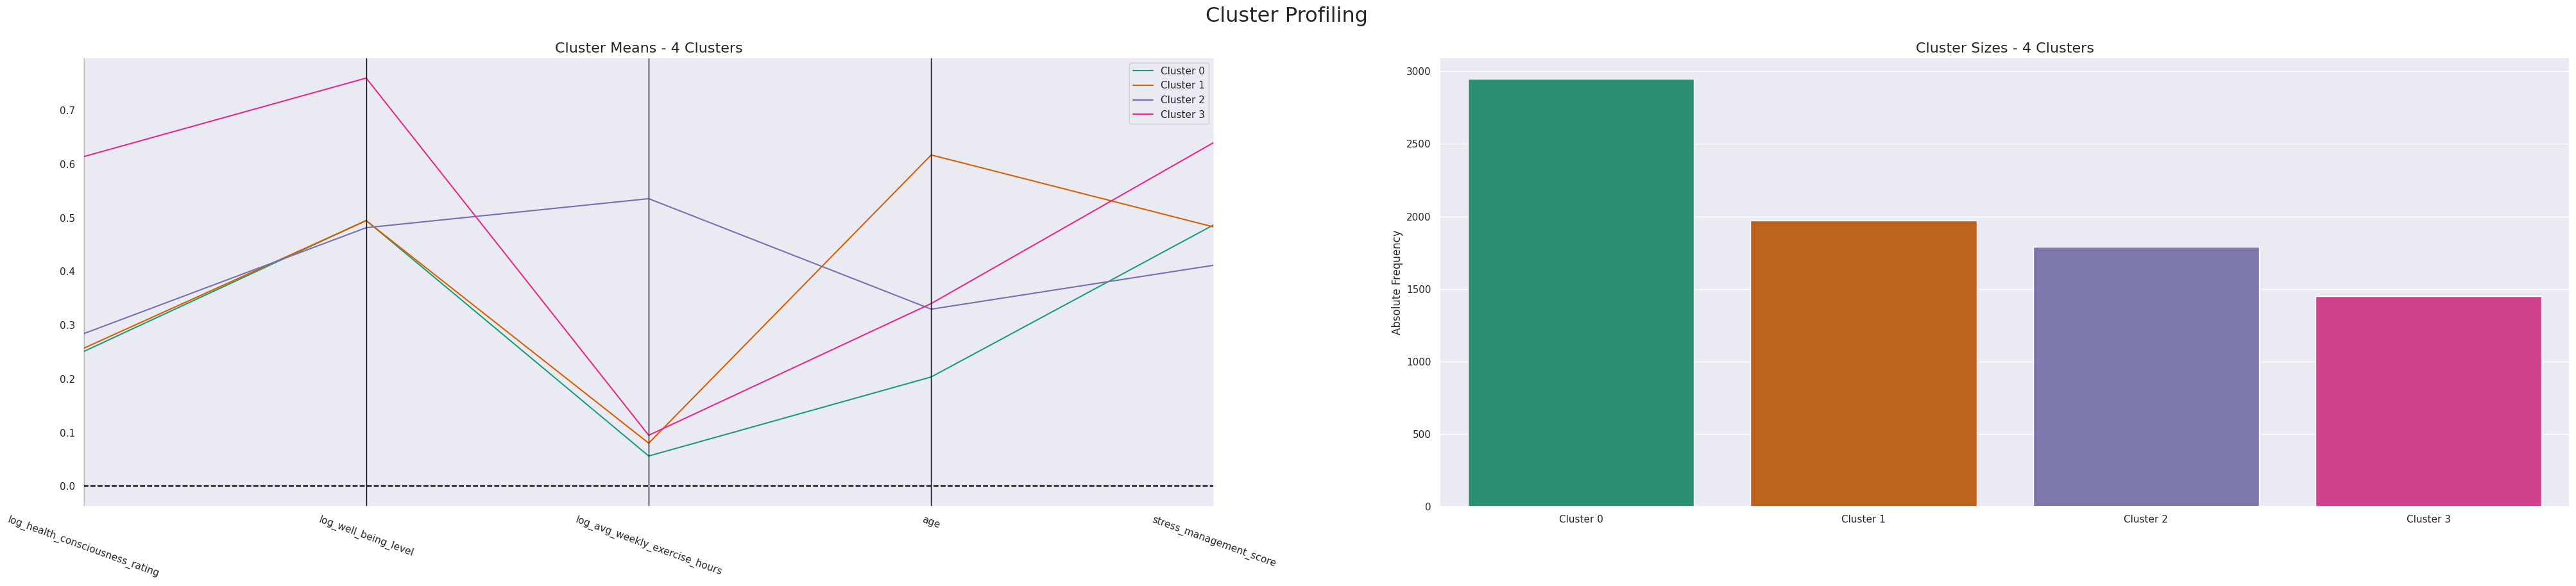

In [35]:
#Visualization
cluster_visualization(health_clustered, ["cluster"], figsize=(50, 10))

With these variables we can see that all the variables influence at least one of the clusters enough to be meaningful to keep them, even the stress_management_score, the variable where they are more similar

We can also conclude that the clusters seem to be almost equally distributed with the exception of cluster 3 that has more observations than the others

#General clustering solution

For this step we decided to start by doing a clustering with all the variables even if the profilings already showed some variables might not be relevant to see the results

Starting with the elbow method to see the ideal K

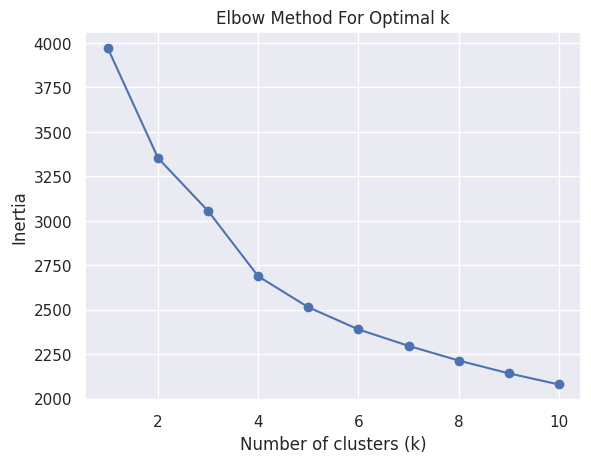

In [36]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    # Correct way to select columns from multiple DataFrames
    selected_columns = list(health_clustered.columns) + list(eco_clustered.columns) + list(social_clustered.columns)
    # Removing duplicate columns (e.g., 'cluster' that appears in all)
    selected_columns = list(dict.fromkeys(selected_columns))
    # Remove 'cluster' from selected_columns if it exists
    selected_columns = [col for col in selected_columns if col != 'cluster']
    kmeans.fit(wd_ct_scaled[selected_columns])
    inertias.append(kmeans.inertia_)

# Plot
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

Also the dendogram to be sure of the right K to use

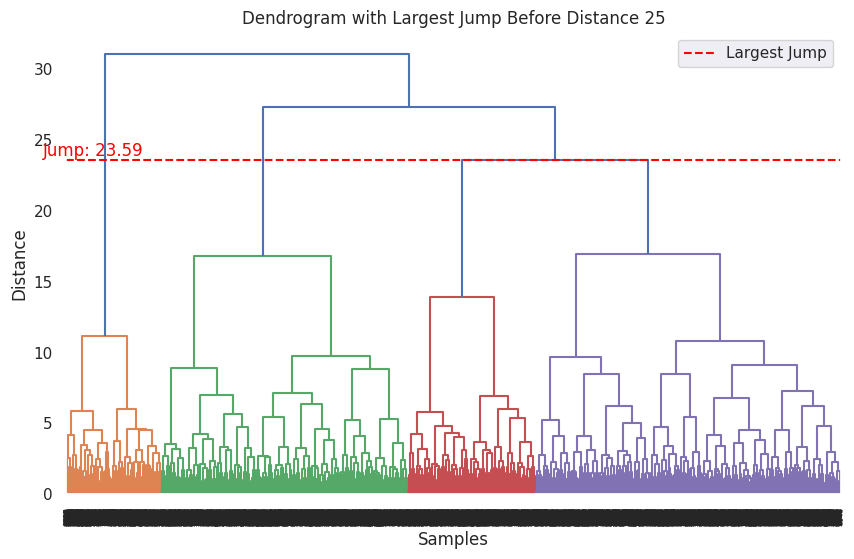

In [37]:
# Assuming wd_ct_scaled and metric_cols are already defined
linkage_matrix = sch.linkage(wd_ct_scaled[selected_columns], method='ward')

# Create the dendrogram
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix)

# Calculate the distances (the last column of the linkage matrix)
distances = linkage_matrix[:, 2]

# Filter distances to find the largest jump before distance 25
filtered_indices = np.where(distances <= 25)[0]
if len(filtered_indices) > 0:
    filtered_distances = distances[filtered_indices]
    max_jump_index = np.argmax(np.diff(filtered_distances))
    max_jump_value = filtered_distances[max_jump_index + 1]  # +1 because np.diff reduces the array size by 1

    # Get the x-coordinate for the largest jump
    x_coord = filtered_indices[max_jump_index + 1]  # +1 to account for the 0-based index

    # Add a horizontal line to mark the largest jump
    plt.axhline(y=max_jump_value, color='red', linestyle='--', label='Largest Jump')

    # Optionally, add a text annotation
    plt.text(x_coord, max_jump_value, f'Jump: {max_jump_value:.2f}', color='red',
             verticalalignment='bottom', horizontalalignment='right')

# Add title and labels
plt.title("Dendrogram with Largest Jump Before Distance 25")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.legend()
plt.show()

After analysing both plots 4 clusters seem to be the appropriate K to continue

In [38]:
kmeans0 = KMeans(n_clusters = 4, random_state = 0).fit(wd_ct_scaled[selected_columns])

In [39]:
wd_ct_scaled['cluster'] = kmeans0.predict(wd_ct_scaled[selected_columns])
wd_ct_metric['cluster'] = kmeans0.predict(wd_ct_scaled[selected_columns])

Visualization of the means of each variable and distributions of observations by cluster

<ipython-input-6-755128967>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:19: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(cluster_labels)


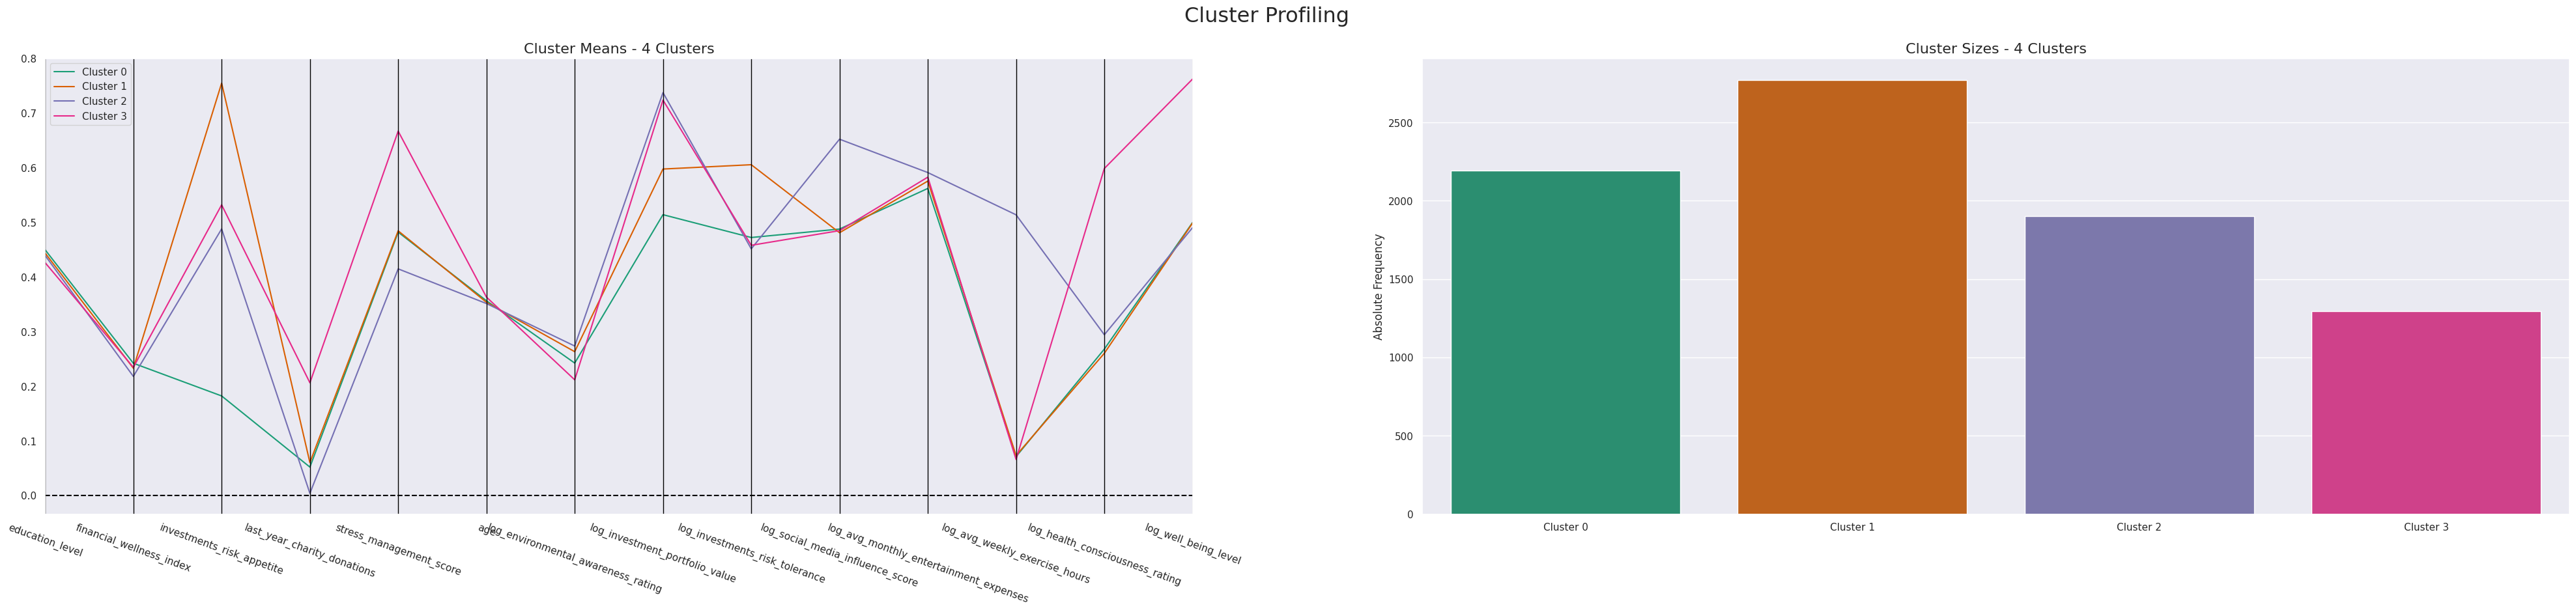

In [40]:
#Visualization

cluster_visualization(wd_ct_metric, ["cluster"], figsize=(50, 10))

Additional visualizations showing more detailed the distribution of each cluster by variable

  0%|          | 0/15 [00:00<?, ?it/s]

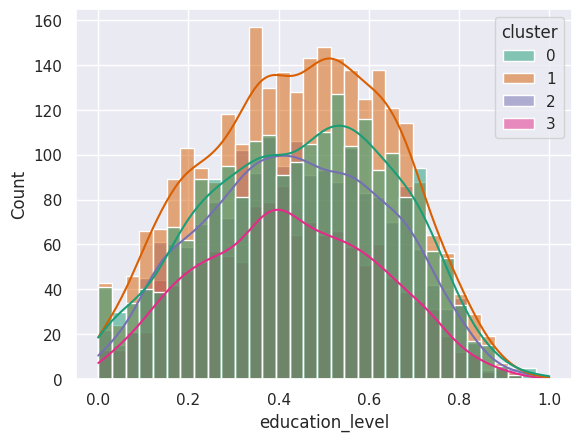

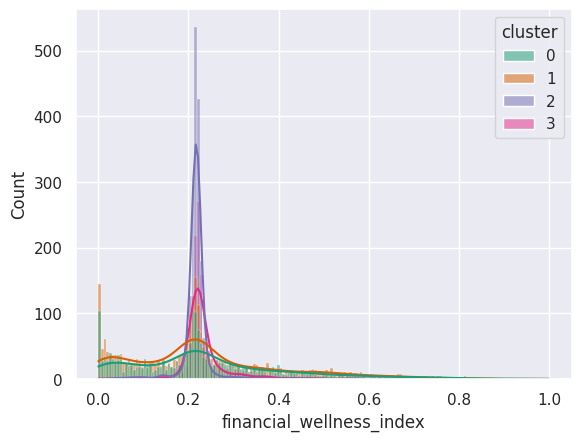

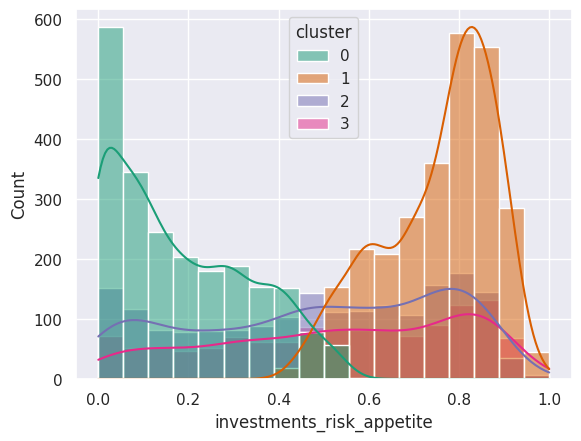

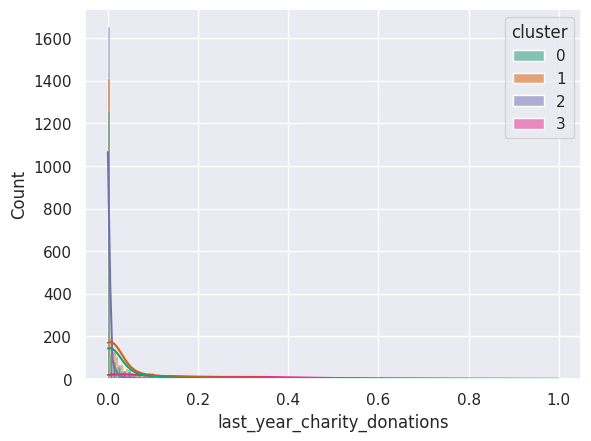

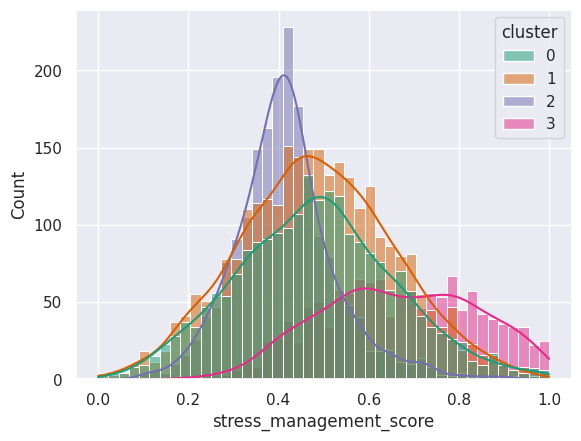

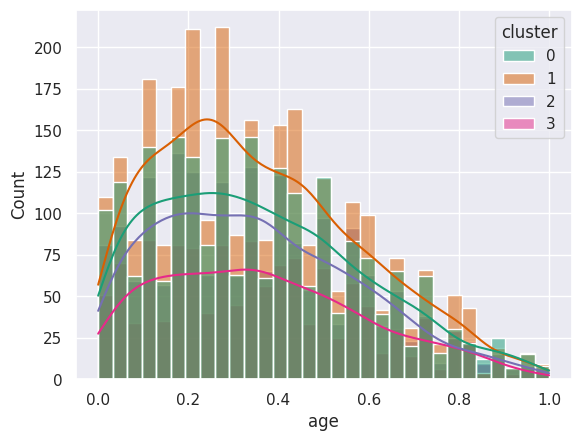

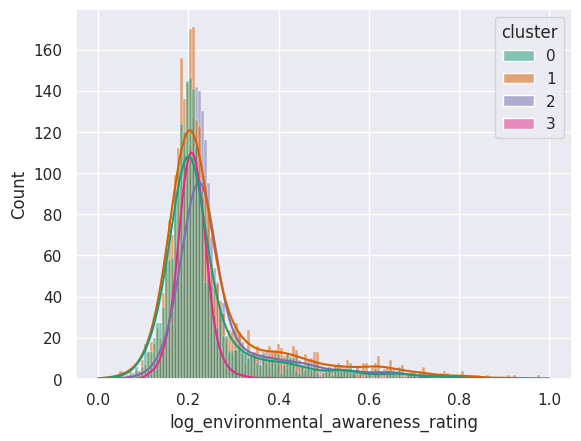

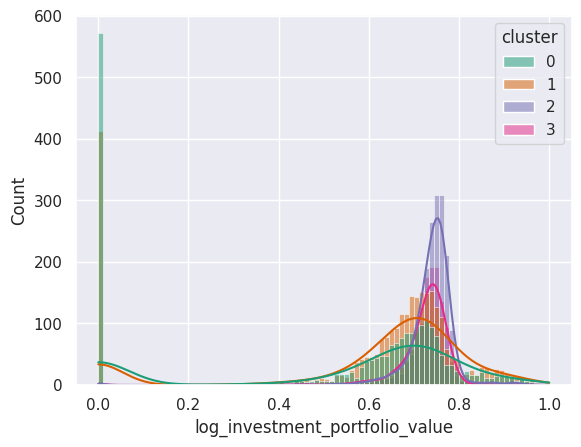

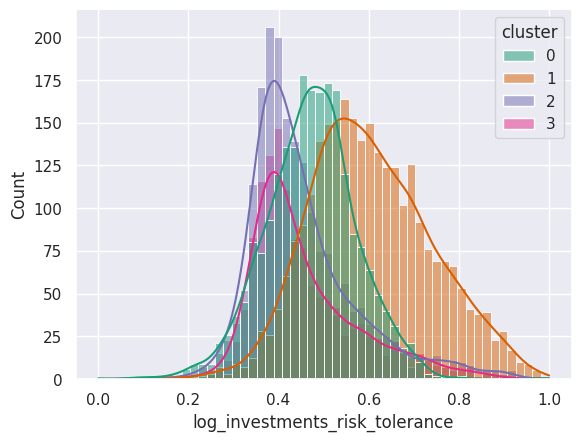

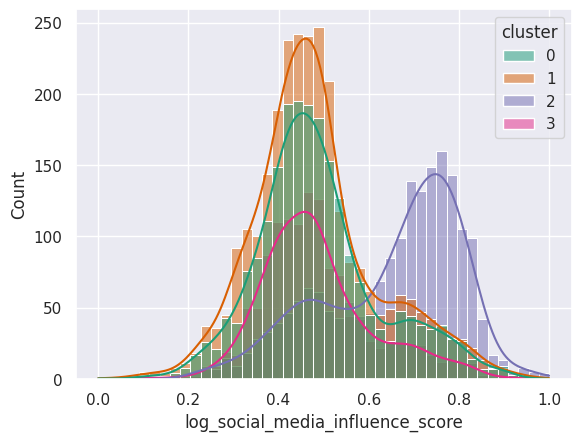

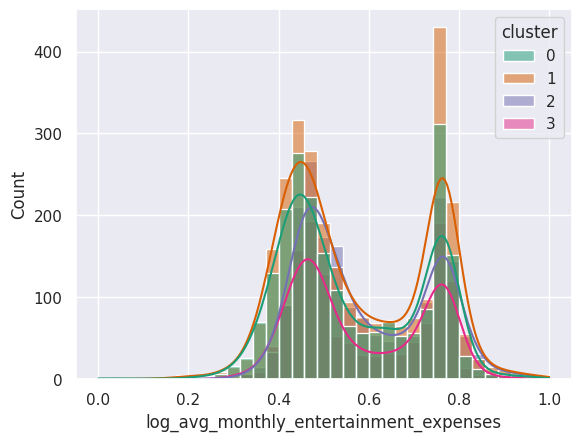

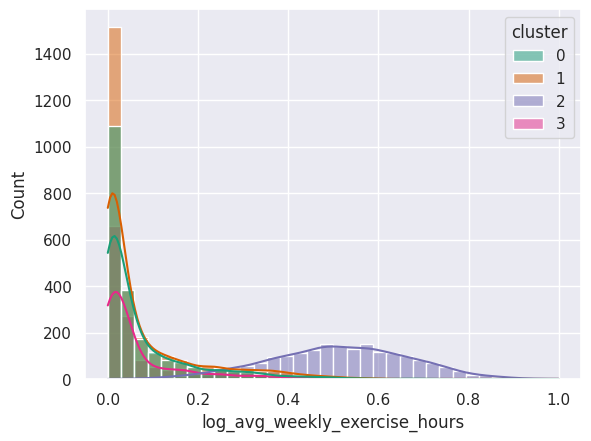

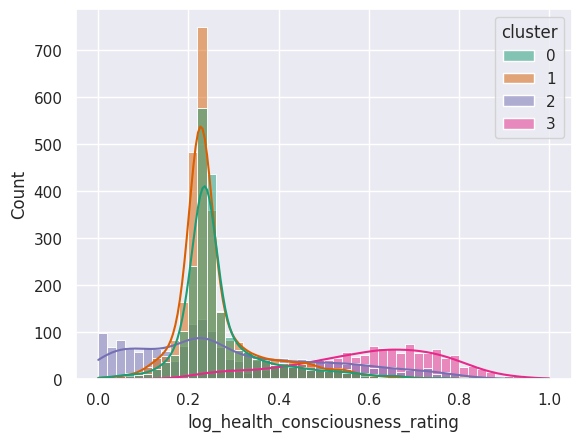

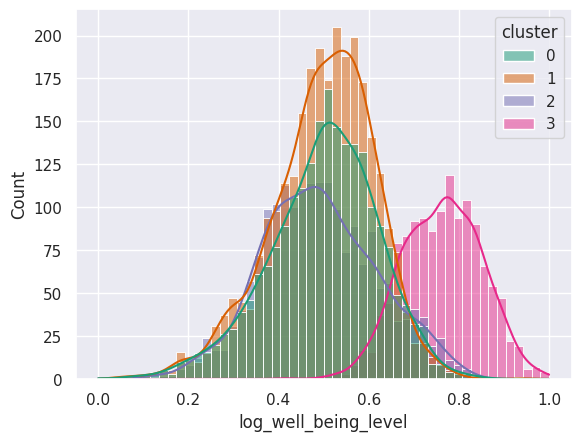

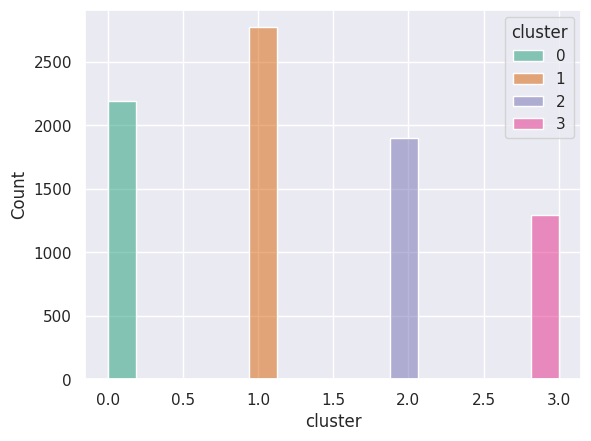

In [41]:
from tqdm.notebook import tqdm, trange
tqdm.pandas(desc="Progress")

for i in tqdm(wd_ct_scaled[wd_ct_metric.columns].columns):
    sns.histplot(wd_ct_scaled[wd_ct_metric.columns], x = i, hue='cluster', kde = True, legend = True, palette = 'Dark2')
    plt.show()

After seeing the initial clusters we decided to do it again but this time without the variable we took out during the social profiling and also log_investment_portfolio_value, log_investments_risk_tolerance, last_year_charity_donations and age

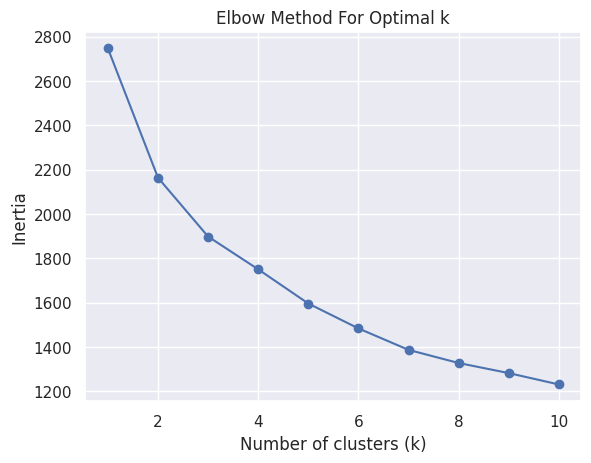

In [42]:
inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    # Correct way to select columns from multiple DataFrames
    selected_columns = list(health_clustered.columns) + list(eco_clustered.columns) + list(social_clustered.columns)

    # Removing unwanted columns
    unwanted_cols = ['log_investment_portfolio_value','log_investments_risk_tolerance','last_year_charity_donations', 'age']
    selected_columns = [col for col in selected_columns if col not in unwanted_cols]

    # Removing duplicate columns (e.g., 'cluster' that appears in all)
    selected_columns = list(dict.fromkeys(selected_columns))
    # Remove 'cluster' from selected_columns if it exists
    selected_columns = [col for col in selected_columns if col != 'cluster']
    kmeans.fit(wd_ct_scaled[selected_columns])
    inertias.append(kmeans.inertia_)

# Plot
plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.show()

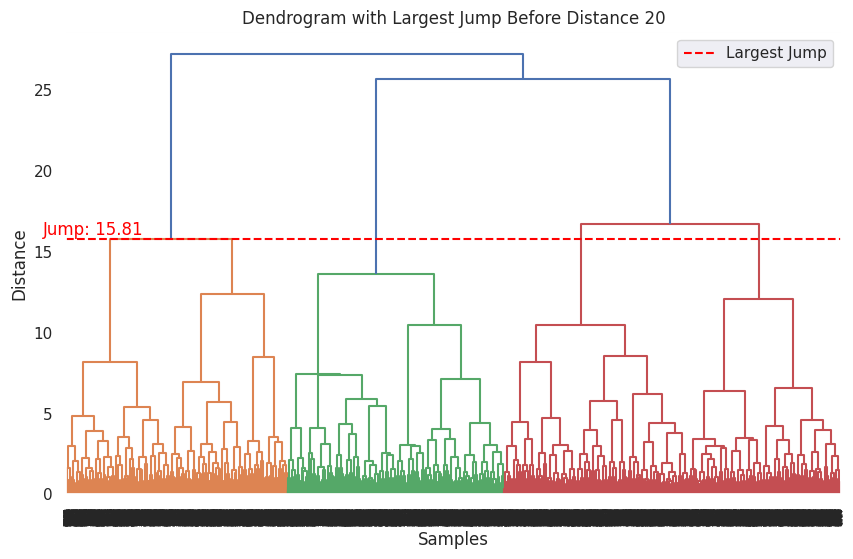

In [43]:
# Assuming wd_ct_scaled and metric_cols are already defined
linkage_matrix = sch.linkage(wd_ct_scaled[selected_columns], method='ward')

# Create the dendrogram
plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(linkage_matrix)

# Calculate the distances (the last column of the linkage matrix)
distances = linkage_matrix[:, 2]

# Filter distances to find the largest jump before distance 20
filtered_indices = np.where(distances <= 20)[0]
if len(filtered_indices) > 0:
    filtered_distances = distances[filtered_indices]
    max_jump_index = np.argmax(np.diff(filtered_distances))
    max_jump_value = filtered_distances[max_jump_index + 1]  # +1 because np.diff reduces the array size by 1

    # Get the x-coordinate for the largest jump
    x_coord = filtered_indices[max_jump_index + 1]  # +1 to account for the 0-based index

    # Add a horizontal line to mark the largest jump
    plt.axhline(y=max_jump_value, color='red', linestyle='--', label='Largest Jump')

    # Optionally, add a text annotation
    plt.text(x_coord, max_jump_value, f'Jump: {max_jump_value:.2f}', color='red',
             verticalalignment='bottom', horizontalalignment='right')

# Add title and labels
plt.title("Dendrogram with Largest Jump Before Distance 20")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.legend()
plt.show()

Despite using less variables this time 4 clusters continued to seem the ideal number

In [44]:
kmeans0 = KMeans(n_clusters = 4, random_state = 0).fit(wd_ct_scaled[selected_columns])

In [45]:
wd_ct_scaled['cluster'] = kmeans0.predict(wd_ct_scaled[selected_columns])
wd_ct_metric['cluster'] = kmeans0.predict(wd_ct_scaled[selected_columns])
selected_columns.append('cluster')

<ipython-input-6-755128967>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:19: UserWarning: The palette list has more values (8) than needed (4), which may not be intended.
  sns.barplot(x=label, y="counts", data=counts, ax=ax[1], palette = color)
<ipython-input-6-755128967>:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[1].set_xticklabels(cluster_labels)


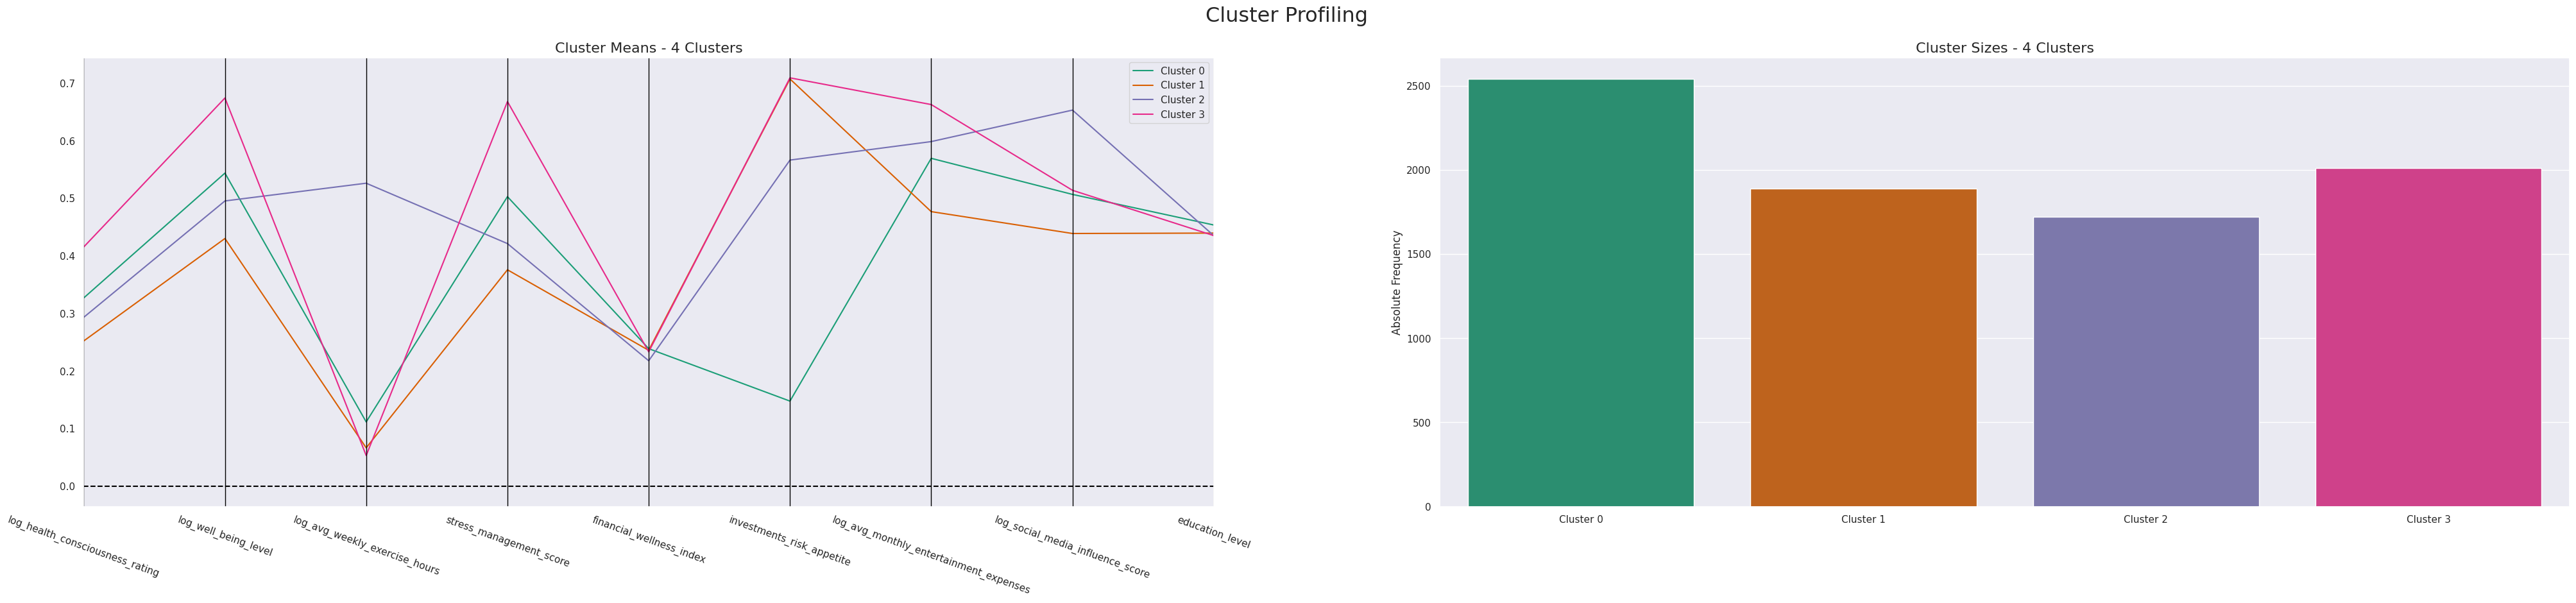

In [46]:
#Visualization

cluster_visualization(wd_ct_scaled[selected_columns], ["cluster"], figsize=(50, 10))

  0%|          | 0/10 [00:00<?, ?it/s]

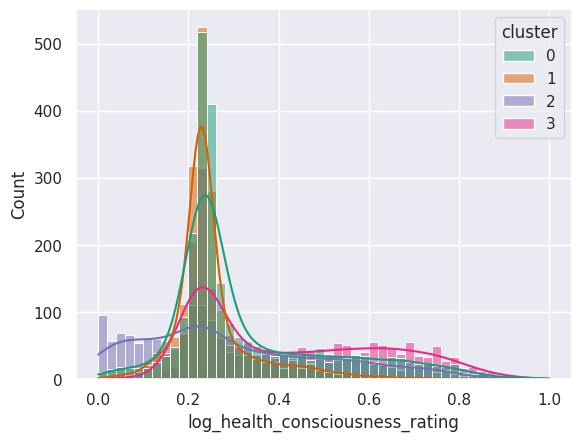

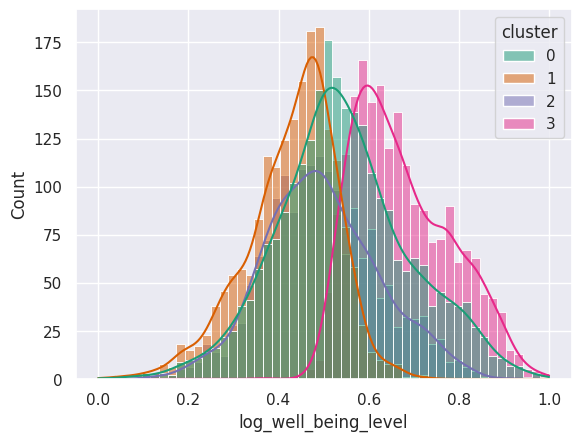

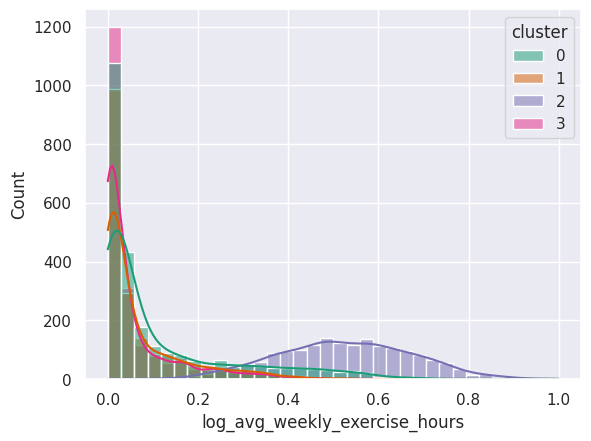

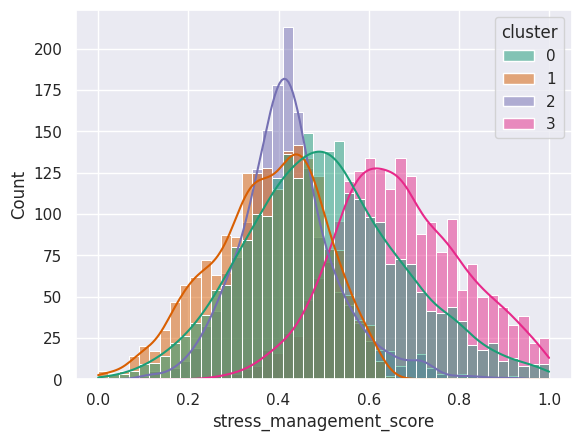

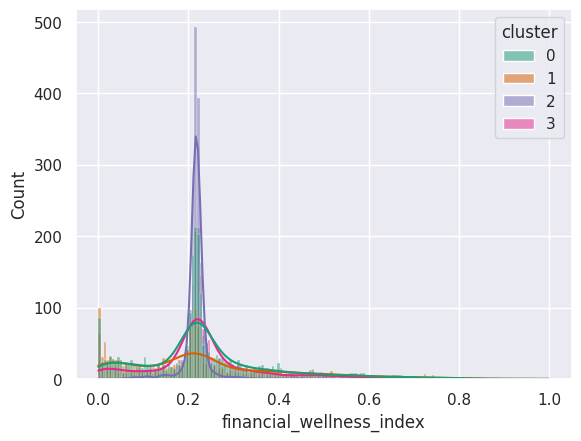

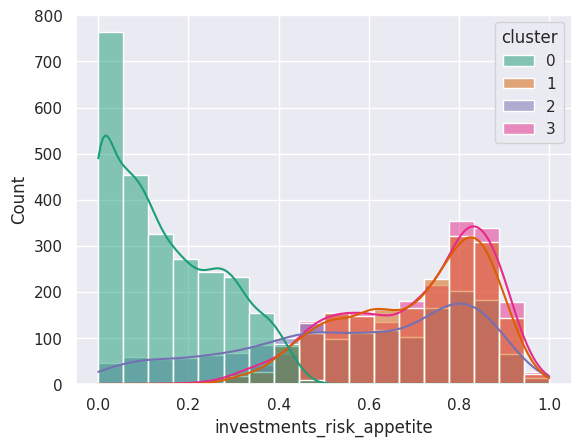

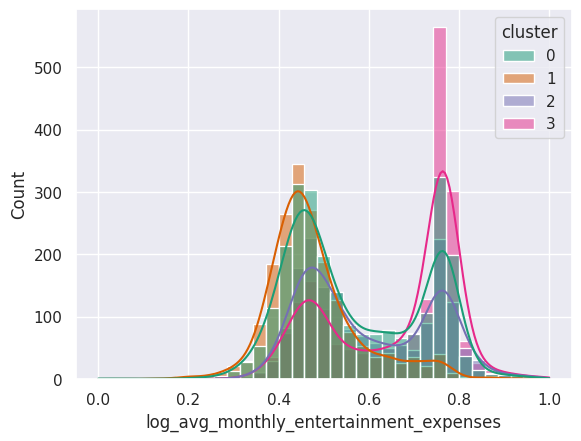

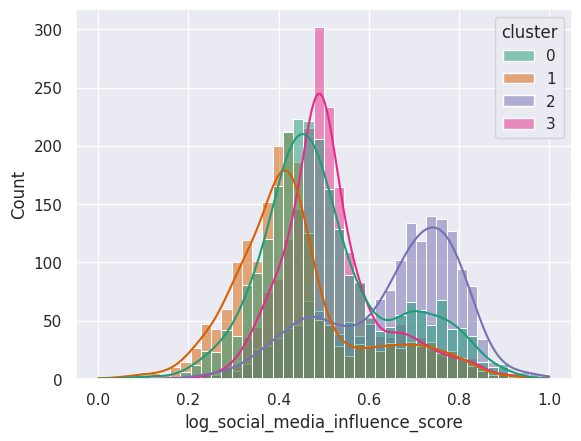

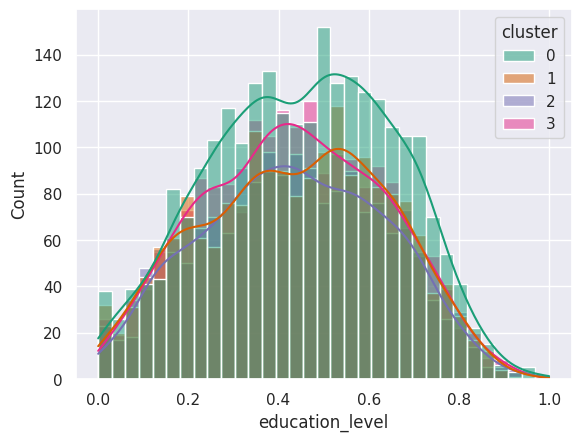

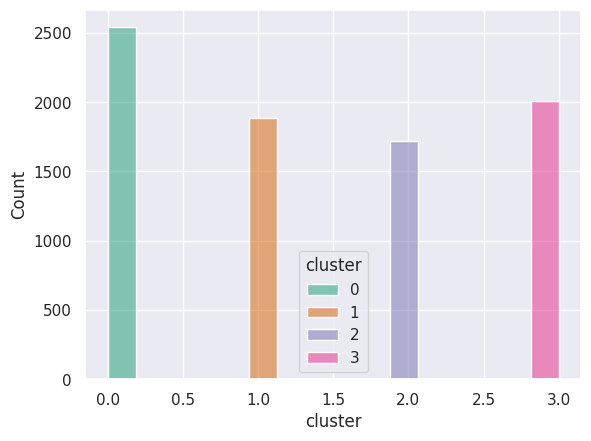

In [47]:
from tqdm.notebook import tqdm, trange
tqdm.pandas(desc="Progress")

for i in tqdm(wd_ct_scaled[selected_columns].columns):
    sns.histplot(wd_ct_scaled[selected_columns], x = i, hue='cluster', kde = True, legend = True, palette = 'Dark2')
    plt.show()

With less variables the means by variables of the clusters are more distributed than before and the observation distribution is also more equally divided

#Solution analysis

##Data to do so

Checking if the cluster column was added to the dataset

In [48]:
wd_ct_scaled.head()

,citizen_id,country,education_level,financial_wellness_index,investments_risk_appetite,last_year_charity_donations,name,stress_management_score,gender,Is_male,...,log_environmental_awareness_rating,log_investment_portfolio_value,is_investor,log_investments_risk_tolerance,log_social_media_influence_score,log_avg_monthly_entertainment_expenses,log_avg_weekly_exercise_hours,log_health_consciousness_rating,log_well_being_level,cluster
0,1,Brazil,0.389315,0.576607,0.780114,0.000000,Mafalda,0.457351,Female,0,...,0.194221,0.387871,Common,0.917684,0.375446,0.465811,0.000000,0.259400,0.490244,1
1,2,New Zealand,0.345058,0.458003,0.837244,0.000000,Olive,0.242076,Female,0,...,0.207002,0.000000,No,0.819880,0.332630,0.504392,0.053708,0.294649,0.542269,1
2,3,Germany,0.662082,0.047127,0.480487,0.000000,Esther,0.615300,Female,0,...,0.216001,0.678226,Common,0.339357,0.701466,0.698048,0.047075,0.145913,0.533085,3
3,4,Germany,0.597648,0.189868,0.820323,0.020218,Ramon,0.495060,Male,1,...,0.209029,0.692416,Common,0.483279,0.516673,0.734570,0.018064,0.236369,0.645044,3
4,5,Turkey,0.427562,0.208099,0.503443,0.000000,Koray,0.325015,Male,1,...,0.345758,0.693531,Common,0.271762,0.646108,0.396071,0.360713,0.085719,0.316992,2


Despite not being used to train the Kmeans, we created a graphs to see if the variables not used have any influence in dividing clusters

See if country show any possible insights regarding the clusters

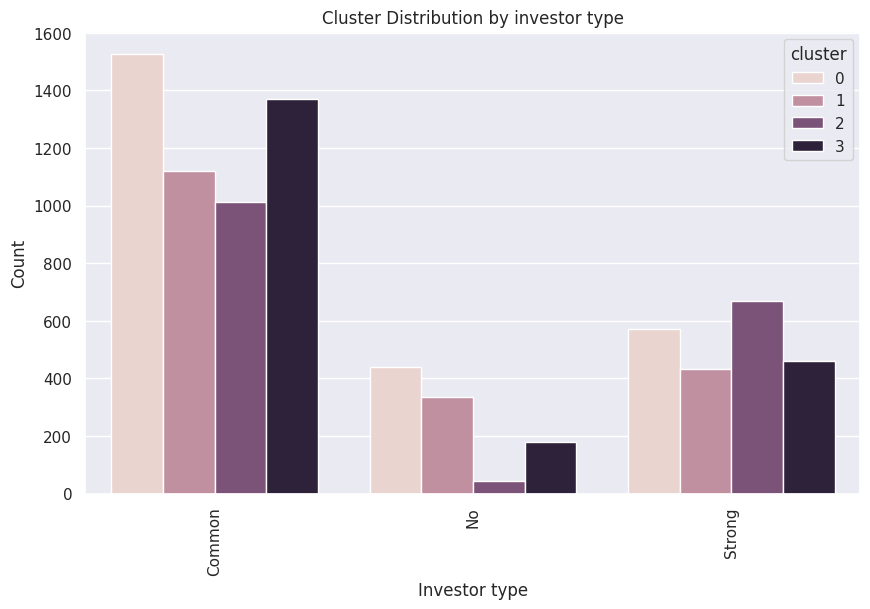

In [49]:
#create a graph that shows the relation between is_investor and cluster
plt.figure(figsize=(10, 6))
sns.countplot(x='is_investor', hue='cluster', data=wd_ct_scaled)
plt.title('Cluster Distribution by investor type')
plt.xlabel('Investor type')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

See if country show any possible insights regarding the clusters

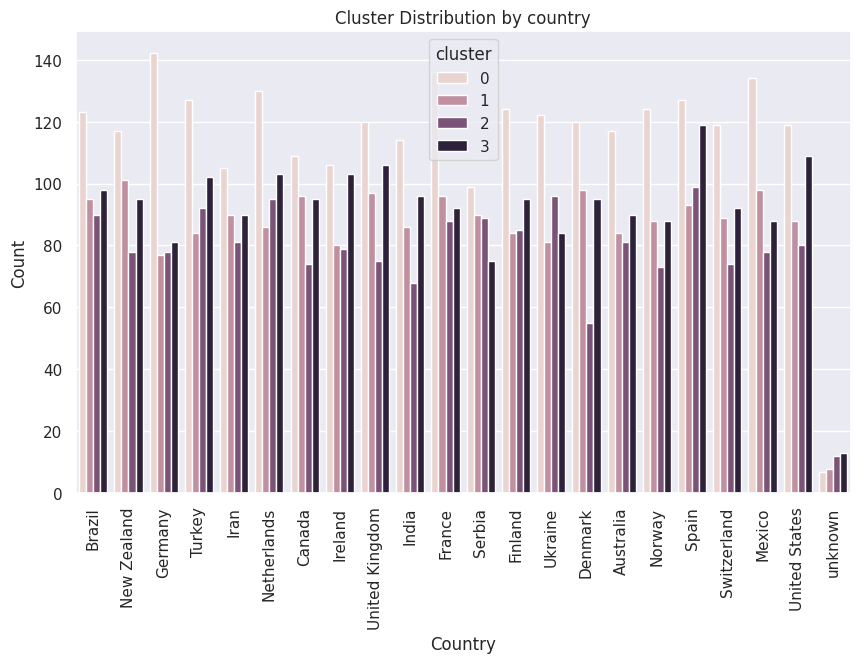

In [50]:
#create a graph that shows the relation between country and cluster
plt.figure(figsize=(10, 6))
sns.countplot(x='country', hue='cluster', data=wd_ct_scaled)
plt.title('Cluster Distribution by country')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

See if gender show any possible insights regarding the clusters

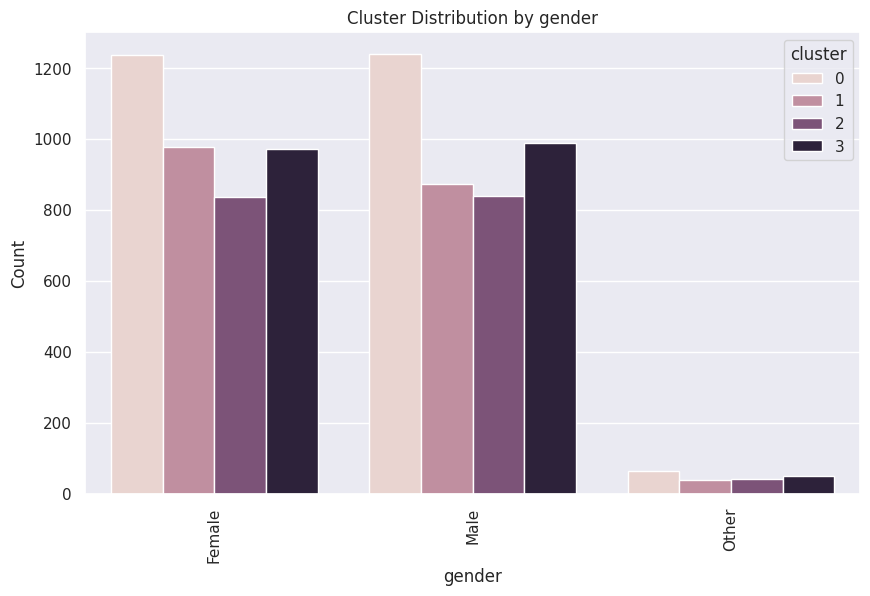

In [51]:
#create a graph that shows the relation between gender and cluster
plt.figure(figsize=(10, 6))
sns.countplot(x='gender', hue='cluster', data=wd_ct_scaled)
plt.title('Cluster Distribution by gender')
plt.xlabel('gender')
plt.ylabel('Count')
plt.xticks(rotation=90)
plt.show()

Another type of visualization of the data in a radar graph to help us with an intepretation of the clusters

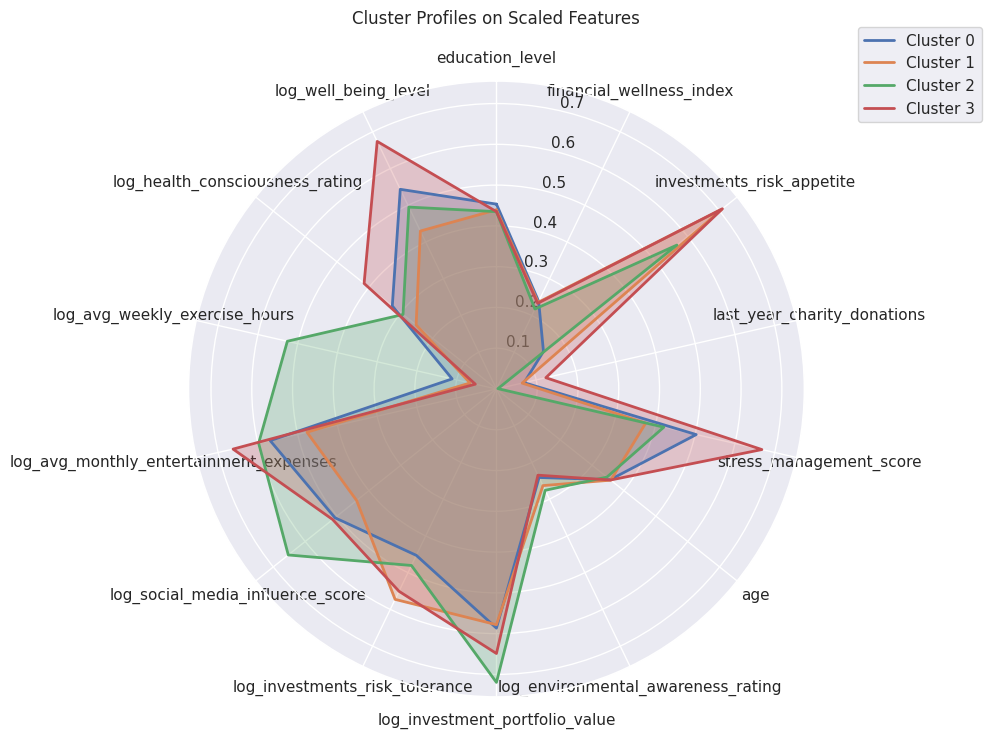

In [52]:
# 1. Compute cluster centroids (means of each feature)
# ---------------------------------------------------
# If you don't yet have a 'cluster' column, do something like:
# from sklearn.cluster import KMeans
# kmeans = KMeans(n_clusters=4, random_state=0).fit(wd_ct_scaled)
# wd_ct_scaled['cluster'] = kmeans.labels_

cluster_centers = wd_ct_scaled[wd_ct_metric.columns].groupby('cluster').mean()

# 2. Prepare the radar‐chart coordinates
# --------------------------------------
features = cluster_centers.columns.tolist()
N = len(features)
# angles for each axis (in radians), plus one more to close the loop
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

# 3. Plot each cluster on the same radar axes
# --------------------------------------------
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

for cluster_label, row in cluster_centers.iterrows():
    values = row.values.flatten().tolist()
    # close the loop
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=f'Cluster {cluster_label}')
    ax.fill(angles, values, alpha=0.25)

# 4. Add feature‐labels around the circle
# ---------------------------------------
# Move the first axis to the top
ax.set_theta_offset(np.pi / 2)
# Flip the direction so labels go clockwise
ax.set_theta_direction(-1)

# Set the labels for each axis
ax.set_thetagrids(np.degrees(angles[:-1]), features)

# 5. Tweak & show
# ----------------
plt.title('Cluster Profiles on Scaled Features', y=1.08)
ax.set_rlabel_position(180 / N)   # move radial labels away from plotted lines
ax.grid(True)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

##Description

We have 4 clusters in the end, with similar sizes among them, being the biggest difference between 0 and 2.

###Cluster 0: **Common citizen**

This cluster that might go unnoticed comparing to the other ones at a first glance,but stands out for its low value of investments risk appetite, that leads to also has low values of investements risk tolerance and portfolio value.

We can conclude that this cluster is probably composed by "common citizens", since it doesnt really stand out in any field.



###Cluster 1: **Investors**

This group is marked by high risk appetite and investment tolerance while having low financial wellness and portfolio, showing they invest a lot but the results may not be the best.

They have low scores in well-being, exercise, and health consciouness, indicating a strong focus on finance over personal wellness.



###Cluster 2: **Influencers**:

This individuals have the highest scores on exercise hours, social media activity, enviromental awareness and high entertainment expenses
 probably being lifestyle influencers.

They are also the ones with highest investment portfolio value, while also having the lowest values on donations.

###Cluster 3: **Caretakers**

This group has the highest scores in well-being, health consciousness, stress management, and charity donations, while also having a high investment value, risk tolerance, and education.

They are well-rounded, purpose-driven lifestyle with a strong emphasis on health and social contribution.


#Aditional insights

##Life style 7 pilars

In [53]:
#https://prescribinglifestyle.com/the-seven-pillars-of-lifestyle-medicine
#https://longevity.stanford.edu/lifestyle/lifestyle-pillars/

According to both standfort and other websites that researched the topic of life style, there are 4 pillars that need to be followed in order to evaluate the lifestyle of an individual.

After, we compare those same pillars with the data collected and analyzed to uncover what could be improved in future studies.

1)	nutrition,

2)	sleep,

3)	fitness,

4)	stress management,

5)	social relationships,

6)	passion and purpose,

7)	cognitive enhancement

Covered pillars: Fitness, Stress Management, Social Relationships and Passion & Purpose are actively represented the data analyzed.

Under-represented: Nutrition and Sleep are entirely missing—adding these would give a fuller view of “wellness”, and help futures researchers to accomplish better results

Partially covered: Cognitive Enhancement currently relies on indirect proxies like education, future researchers might profit from considering dedicated measures (e.g. learning hours, brain-training activity).

By filling these gaps—especially Nutrition and Sleep future researchers be able to segment better the population across all seven pillars, strengthening both the interpretability of each cluster and the design of targeted interventions.

###Conclusion

In light of established frameworks from Stanford and other expert sources, a comprehensive evaluation of individual lifestyles hinges on seven key pillars: nutrition, sleep, fitness, stress management, social relationships, passion & purpose, and cognitive enhancement. Our current dataset robustly captures fitness, stress management, social engagement and personal growth, but lacks direct measures for nutrition and sleep, and relies on indirect proxies for cognitive enhancement. To achieve a truly holistic understanding—and to enable more precise, actionable segmentation in future research—dedicated data collection should be extended to include dietary habits and sleep quality metrics, as well as explicit indicators of cognitive activity (e.g. learning hours, brain-training exercises). By addressing these gaps, subsequent studies will be better equipped to reflect the full spectrum of well-being, improve cluster interpretability, and design targeted interventions that foster healthier, more balanced lifestyles.